# EXP-035 — Huấn luyện DenseNet121 + YOLO26s (NEG_V04)

Notebook này lặp lại **đúng EXP-034** (DenseNet121 5 seed hai giai đoạn + YOLO26s đã khóa + logistic stacker F3), chỉ thay **thành phần YOLO**:

| | EXP-034 | EXP-035 |
|---|---|---|
| Dataset YOLO | `CASHEW_YOLO_MASTER_FINAL_NEG_V03 (2).zip` | `CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip` |
| Detector | `EXP-Y26S-NEG-V03-001` | `EXP-Y26S-NEG-V04-001` (`EXP-Y26S-NEG-V04-001_FULL.zip`) |
| YOLO train/val/test | 3497/951/412 (ảnh nền 621/58/0) | 3739/1076/488 (ảnh nền 863/183/76) |
| Val mAP50 / mAP50-95 | 0.7163 / 0.3981 | 0.7144 / 0.3998 |

Lý do: ViT (`EXP-VIT-YOLO-PIPELINE-034`) đã dùng YOLO NEG_V04, còn DenseNet121/ResNet50 dùng NEG_V03. EXP-035 đưa DenseNet121 về cùng detector để so sánh công bằng. Công thức DenseNet, seed, BOX_CONF, cách fit stacker và báo cáo giữ nguyên như EXP-034.

Chạy lần lượt tất cả cell trong Colab GPU. Cell cuối upload `ANALYSIS.zip` và `FULL.zip` lên Google Drive. `EXP035_DRY_RUN=1` chỉ kiểm tra notebook với dữ liệu tổng hợp, không tạo kết quả thực nghiệm.


## Quy trình

1. Cấu hình và xác minh Split13, Holdout 09, dataset YOLO NEG_V04 (SHA-256) và `best.pt` của EXP-Y26S-NEG-V04-001 (SHA-256, lấy từ `EXP-Y26S-NEG-V04-001_FULL.zip` trên Drive).
2. Kiểm tra trùng ảnh với YOLO NEG_V04 train, chạy YOLO để lấy bằng chứng vùng bệnh, giữ BOX_CONF=0.25 như EXP-034.
3. Huấn luyện DenseNet121 5 seed theo hai giai đoạn (giống EXP-034). Tùy chọn `SEED_MODELS_SOURCE_EXPERIMENT_ID` cho phép dùng lại 5 model DenseNet của EXP-034 để chỉ YOLO thay đổi.
4. Fit logistic stacker trên clean Validation theo GroupKFold; khóa `C`, temperature và ngưỡng từ chối trước khi đọc Test/Holdout.
5. Đánh giá **chỉ pipeline kết hợp** trên Test, Holdout và YOLO Test localization; xuất CSV, biểu đồ, ảnh ví dụ và kiểm tra pipeline triển khai.
6. Tạo ZIP và xác minh upload lên Google Drive.

Lưu ý so với EXP-034: tập clean Validation (loại ảnh gần trùng YOLO train) được tính lại theo NEG_V04 nên có thể khác một chút. YOLO Test của NEG_V04 có 76 ảnh nền 0 box (lá khỏe, lá lạ có bệnh), vì vậy precision định vị trên subset `all` tính cả box vẽ nhầm lên ảnh nền. Holdout 09 từng được xem trong EXP-032, báo cáo gọi là holdout mô tả, không coi là blind benchmark.


In [1]:
# EXP-035 combined training configuration and imports
import base64, csv, gc, hashlib, io, json, os, platform, shutil, stat, subprocess, sys, time, zipfile
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageOps
from scipy.stats import norm
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, log_loss, precision_recall_fscore_support)
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import joblib
import importlib.util

EXPERIMENT_ID = "EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04"
SEEDS = [42, 123, 2026, 3407, 7777]
CLASSES = ["anthracnose", "healthy", "leaf_miner", "red_rust", "not_cashew_leaf"]
DETECTOR_CLASSES = ["anthracnose", "leaf_miner", "red_rust"]
CLASS_NAMES = CLASSES
CLASS_INDEX = {name: i for i, name in enumerate(CLASSES)}
DATASET_ARCHIVE_NAME = "CashewData_Split (13).zip"
DATASET_ARCHIVE_FILE_ID = "1HUE5ObO1vW0mP2QjgsdObMuW4RVPzNk7"
DATASET_ARCHIVE_EXPECTED_BYTES = 1470301553
DATASET_ARCHIVE_SHA256 = "e1647b72e10af04275dc760545f4ef17c9f44343ae119495b89ba1e3cd954e04"
REAL_HOLDOUT_ARCHIVE_NAME = "RL_Cashew_holdout (9).zip"
REAL_HOLDOUT_ARCHIVE_FILE_ID = "1QW2JYx8K6zkTs9y34f39OTBlxUOjWosZ"
REAL_HOLDOUT_EXPECTED_BYTES = 370947341
# YOLO26s NEG_V04 (same detector as EXP-VIT-YOLO-PIPELINE-034).
YOLO_DATASET_ARCHIVE_NAME = "CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip"
YOLO_DATASET_FILE_ID = "1V-_ebnmU6SUnNvXC3a2kQPCQvvTimFXr"
YOLO_DATASET_EXPECTED_BYTES = 287009072
YOLO_DATASET_SHA256 = "4dca7b48a07fb971ef7f4e7c3b8cbe5b67f17bc411a7d43c060cece2e9e5798b"
YOLO_DATASET_FINGERPRINT = "edc28c5d5c7f12e83fdaff6509263a0085d19e7a9fd9e83297f5cfd5bddd66fa"
DRIVE_TARGET_FOLDER_ID = "1DGKTnzsvVc60RIEn5lQgflR3s-loM24G"
DETECTOR_NAME = "EXP-Y26S-NEG-V04-001"
DETECTOR_FULL_ZIP = "EXP-Y26S-NEG-V04-001_FULL.zip"
DETECTOR_FULL_ZIP_FILE_ID = "1DTTWYUWcDFJzHW-4p91Z2W8LJxiI8Zwq"
DETECTOR_FULL_ZIP_EXPECTED_BYTES = 58702426
DETECTOR_WEIGHTS_MEMBER = "train/weights/best.pt"
DETECTOR_WEIGHTS_SHA256 = "f9dc3fba1347b3213819f61abddb36b07e455112d4e6e8d57eeeeca8ab1b7f4a"
# None: train DenseNet121 from scratch exactly like EXP-034.
# "EXP-DENSENET121-YOLO-COMBINED-TRAINING-034": reuse its five verified seed models from
# DRIVE_TARGET_FOLDER_ID so that only the YOLO component differs.
SEED_MODELS_SOURCE_EXPERIMENT_ID = None
DATASET_ARCHIVE_OVERRIDE = None
REAL_HOLDOUT_ARCHIVE_OVERRIDE = None
YOLO_DATASET_OVERRIDE = None
DETECTOR_WEIGHTS_OVERRIDE = None
RUN_PART_B = True
UPLOAD_RESULT_ZIPS_TO_DRIVE = True
USE_EXTRA_BLIND_SET = False
EXTRA_BLIND_DRIVE_FOLDER_ID = ""  # Required only when USE_EXTRA_BLIND_SET is True.
DRY_RUN = os.environ.get("EXP035_DRY_RUN") == "1"  # Synthetic fixture only; never a real experiment result.
if USE_EXTRA_BLIND_SET:
    assert EXTRA_BLIND_DRIVE_FOLDER_ID.strip()
if DRY_RUN:
    RUN_PART_B, UPLOAD_RESULT_ZIPS_TO_DRIVE = True, False
    SEED_MODELS_SOURCE_EXPERIMENT_ID = None
else:
    for package,module in (("google-api-python-client","googleapiclient"),
                           ("google-auth","google.auth")):
        try: found=importlib.util.find_spec(module)
        except ModuleNotFoundError: found=None
        if found is None: subprocess.check_call([sys.executable,"-m","pip","install",package])
PROJECT_ROOT = Path("/content") if Path("/content").is_dir() else Path.cwd()
OUT_DIR = PROJECT_ROOT / "training_results" / "current_dataset" / (EXPERIMENT_ID + ("-DRYRUN" if DRY_RUN else ""))
AGGREGATE = OUT_DIR / "aggregate"
AGGREGATE.mkdir(parents=True, exist_ok=True)
STAGE_ROOT = PROJECT_ROOT / "exp035_inputs"
YOLO_INFERENCE_CONF, YOLO_INFERENCE_IOU, YOLO_IMGSZ = 0.05, 0.7, 640
IMG_SIZE, BATCH_SIZE = 256, 16
STAGE1_LR, STAGE1_EPOCHS = 3e-4, 12
STAGE2_LR, STAGE2_EPOCHS = 1e-5, 30
WEIGHT_DECAY, HEAD_DROPOUT = 1e-4, 0.40
REAL_OVERSAMPLE_FACTOR, SELECTION_PRIMARY_METRIC = 1, "val_loss"
if DRY_RUN:
    SEEDS, STAGE1_EPOCHS, STAGE2_EPOCHS = [42, 123], 1, 1

def file_md5(path):
    digest = hashlib.md5()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

def write_json(path, value):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(value, indent=2, sort_keys=True, default=str), encoding="utf-8")

def unique_keys(frame, label):
    if frame["evidence_key"].duplicated().any():
        raise ValueError(f"{label}: duplicate split/class/filename keys")
    if any(len(str(key).split("/")) != 3 for key in frame["evidence_key"]):
        raise ValueError(f"{label}: keys must be split/class/filename")

def checked_join(left, right, label):
    unique_keys(left, label + " left")
    unique_keys(right, label + " right")
    a, b = set(left.evidence_key), set(right.evidence_key)
    if a != b:
        raise ValueError(f"{label}: key mismatch; missing={sorted(a-b)[:3]} extra={sorted(b-a)[:3]}")
    return left.merge(right, on="evidence_key", validate="one_to_one")

print("EXP-035", platform.python_version(), "dry_run", DRY_RUN,
      "DenseNet training", RUN_PART_B)
print("Detector", DETECTOR_NAME, "Val mAP50=0.7144 mAP50-95=0.3998; "
      "YOLO train/val/test=3739/1076/488 (negatives 863/183/76).")
print("DenseNet seed models:", SEED_MODELS_SOURCE_EXPERIMENT_ID or "train from scratch")
print("Detector config FINAL_TEST_EVALUATION=false; YOLO Test is the clean localization split.")


EXP-035 3.13.16 dry_run False DenseNet training True
Detector EXP-Y26S-NEG-V04-001 Val mAP50=0.7144 mAP50-95=0.3998; YOLO train/val/test=3739/1076/488 (negatives 863/183/76).
DenseNet seed models: train from scratch
Detector config FINAL_TEST_EVALUATION=false; YOLO Test is the clean localization split.


In [2]:
# Stage pinned inputs. Source helpers copied from EXP-031 by header.
def archive_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(8 << 20), b''):
            digest.update(block)
    return digest.hexdigest()

def source_archive(file_id, name, expected_bytes, override):
    if override:
        path = Path(override).expanduser()
        if not path.is_file():
            raise FileNotFoundError(f'Archive override missing: {path}')
    else:
        path = STAGE_ROOT / 'archives' / name
        path.parent.mkdir(parents=True, exist_ok=True)
        if not path.is_file() or path.stat().st_size != expected_bytes or not zipfile.is_zipfile(path):
            if not file_id:
                raise FileNotFoundError(f'{name}: set a Drive file ID or archive override')
            import google.auth
            from googleapiclient.discovery import build
            from googleapiclient.http import MediaIoBaseDownload
            if Path('/content').is_dir():
                from google.colab import auth
                auth.authenticate_user()
            credentials, _ = google.auth.default(scopes=['https://www.googleapis.com/auth/drive.readonly'])
            service = build('drive', 'v3', credentials=credentials, cache_discovery=False)
            meta = service.files().get(fileId=file_id, fields='id,name,size,md5Checksum',
                                       supportsAllDrives=True).execute()
            if meta['name'] != name or int(meta['size']) != expected_bytes:
                raise ValueError(f'Drive source differs from expected {name}: {meta}')
            partial = path.with_suffix(path.suffix + '.part')
            request = service.files().get_media(fileId=file_id, supportsAllDrives=True)
            with partial.open('wb') as stream:
                downloader = MediaIoBaseDownload(stream, request, chunksize=8 << 20)
                done = False
                while not done:
                    progress, done = downloader.next_chunk(num_retries=3)
                    if progress:
                        print(name, f'{progress.progress():.0%}')
            if partial.stat().st_size != expected_bytes or not zipfile.is_zipfile(partial):
                raise RuntimeError(f'Incomplete archive download: {name}')
            if meta.get('md5Checksum'):
                digest = hashlib.md5()
                with partial.open('rb') as stream:
                    for block in iter(lambda: stream.read(8 << 20), b''):
                        digest.update(block)
                if digest.hexdigest() != meta['md5Checksum']:
                    raise RuntimeError(f'Drive MD5 mismatch: {name}')
            partial.replace(path)
    if path.stat().st_size != expected_bytes or not zipfile.is_zipfile(path):
        raise ValueError(f'Archive size/type mismatch: {path}')
    return path

def extract_verified(archive_path, destination):
    archive_path, destination = Path(archive_path), Path(destination)
    checksum = archive_sha256(archive_path)
    marker = destination / '.archive_sha256'
    if destination.is_dir():
        if not marker.is_file() or marker.read_text(encoding='utf-8').strip() != checksum:
            raise RuntimeError(f'Unverified/incomplete extraction: {destination}')
        return destination
    staging = destination.with_name(destination.name + '_staging')
    if staging.exists():
        raise RuntimeError(f'Incomplete staging directory: {staging}')
    staging.mkdir(parents=True)
    with zipfile.ZipFile(archive_path) as archive:
        resolved_root = staging.resolve()
        for member in archive.infolist():
            target = (staging / member.filename.replace('\\', '/')).resolve()
            if (stat.S_ISLNK(member.external_attr >> 16) or
                    not target.is_relative_to(resolved_root)):
                raise ValueError(f'Unsafe archive member: {member.filename}')
        archive.extractall(staging)
    (staging / '.archive_sha256').write_text(checksum + '\n', encoding='utf-8')
    staging.rename(destination)
    return destination


def ensure_detector_weights(project_root, override, archive_name, file_id,
                            archive_bytes, weights_member, weights_sha256):
    """Return a verified NEG_V04 best.pt extracted from the YOLO FULL ZIP on Drive."""
    weights = (Path(override).expanduser() if override
               else Path(project_root) / 'detector' / 'neg_v04_best.pt')
    if weights.is_file():
        found = file_sha256(weights)
        if found != weights_sha256:
            raise ValueError(f'YOLO best.pt SHA256 mismatch: {found}')
        print('Verified YOLO best.pt:', weights, found[:16])
        return weights
    if override:
        raise FileNotFoundError(f'DETECTOR_WEIGHTS_OVERRIDE does not exist: {weights}')
    archive_path = source_archive(file_id, archive_name, archive_bytes, None)
    with zipfile.ZipFile(archive_path) as archive:
        if archive.testzip() is not None:
            raise ValueError(f'Corrupt YOLO FULL ZIP: {archive_path}')
        members = [n for n in archive.namelist()
                   if n == weights_member or n.endswith('/' + weights_member)]
        if len(members) != 1:
            raise RuntimeError(f'{archive_name}: expected one {weights_member}, found {members}')
        checkpoint = archive.read(members[0])
    found_weights = hashlib.sha256(checkpoint).hexdigest()
    if found_weights != weights_sha256:
        raise ValueError(f'YOLO best.pt SHA256 mismatch: {found_weights}')
    weights.parent.mkdir(parents=True, exist_ok=True)
    temp_weights = weights.with_suffix('.pt.part')
    temp_weights.write_bytes(checkpoint)
    temp_weights.replace(weights)
    print('Verified YOLO best.pt from', archive_path, '|', members[0],
          '| SHA256', found_weights[:16])
    return weights


import urllib.request
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def image_files(root):
    return sorted(p for p in Path(root).rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES)

def dataset_root(extracted, kind):
    candidates = [Path(extracted), *[p for p in Path(extracted).rglob("*") if p.is_dir()]]
    if kind == "split13":
        matches = [p for p in candidates if (p / "train").is_dir() and (p / "val").is_dir() and (p / "test").is_dir()]
    elif kind == "holdout09":
        matches = [p for p in candidates if all((p / c).is_dir() for c in CLASSES[:4]) and
                   len([q for q in p.iterdir() if q.is_dir()]) == 4]
    elif kind == "yolo":
        matches = [p for p in candidates if all((p / "images" / s).is_dir() and (p / "labels" / s).is_dir()
                   for s in ("train", "val", "test"))]
    else:
        raise ValueError(kind)
    if len(matches) != 1:
        raise RuntimeError(f"{kind}: expected one root, found {matches}")
    return matches[0]

def synthetic_fixture():
    import tempfile
    root = STAGE_ROOT / "synthetic_exp033"
    if root.exists():
        shutil.rmtree(root)
    split_root, hold_root, yolo_root = root / "split13", root / "holdout09", root / "yolo"
    rng = np.random.default_rng(33)
    for split, classes, per_class in (("train", CLASSES, 2), ("val", CLASSES, 6),
                                      ("test", CLASSES, 2), ("holdout", CLASSES[:4], 2)):
        for ci, cls in enumerate(classes):
            for i in range(per_class):
                target = (hold_root if split == "holdout" else split_root / split) / cls / f"{cls}_{split}_{i}.png"
                target.parent.mkdir(parents=True, exist_ok=True)
                pixels = rng.integers(0, 255, (48, 48, 3), dtype=np.uint8)
                pixels[:, :, ci % 3] = np.clip(pixels[:, :, ci % 3].astype(int) + 45, 0, 255)
                Image.fromarray(pixels.astype(np.uint8)).save(target)
    for split, count in (("train", 10), ("val", 6), ("test", 6)):
        for i in range(count):
            image = yolo_root / "images" / split / f"{'real_' if i % 2 else ''}{split}_{i}.png"
            label = yolo_root / "labels" / split / (image.stem + ".txt")
            image.parent.mkdir(parents=True, exist_ok=True)
            label.parent.mkdir(parents=True, exist_ok=True)
            Image.fromarray(rng.integers(0, 255, (48, 48, 3), dtype=np.uint8)).save(image)
            label.write_text(f"{i % 3} 0.5 0.5 0.4 0.4\n", encoding="utf-8")
    return split_root, hold_root, yolo_root

if DRY_RUN:
    SPLIT13_ROOT, HOLDOUT_ROOT, YOLO_ROOT = synthetic_fixture()
    DETECTOR_WEIGHTS_PATH = None
    print("Synthetic fixture:", SPLIT13_ROOT, HOLDOUT_ROOT, YOLO_ROOT)
else:
    split_archive = source_archive(DATASET_ARCHIVE_FILE_ID, DATASET_ARCHIVE_NAME,
                                   DATASET_ARCHIVE_EXPECTED_BYTES, DATASET_ARCHIVE_OVERRIDE)
    assert file_sha256(split_archive) == DATASET_ARCHIVE_SHA256
    hold_archive = source_archive(REAL_HOLDOUT_ARCHIVE_FILE_ID, REAL_HOLDOUT_ARCHIVE_NAME,
                                  REAL_HOLDOUT_EXPECTED_BYTES, REAL_HOLDOUT_ARCHIVE_OVERRIDE)
    yolo_archive = source_archive(YOLO_DATASET_FILE_ID, YOLO_DATASET_ARCHIVE_NAME,
                                  YOLO_DATASET_EXPECTED_BYTES, YOLO_DATASET_OVERRIDE)
    if file_sha256(yolo_archive) != YOLO_DATASET_SHA256:
        raise ValueError(f"YOLO NEG_V04 ZIP SHA256 mismatch: {yolo_archive}")
    SPLIT13_ROOT = dataset_root(extract_verified(split_archive, STAGE_ROOT / "split13"), "split13")
    HOLDOUT_ROOT = dataset_root(extract_verified(hold_archive, STAGE_ROOT / "holdout09"), "holdout09")
    YOLO_ROOT = dataset_root(extract_verified(yolo_archive, STAGE_ROOT / "yolo"), "yolo")
    DETECTOR_WEIGHTS_PATH = ensure_detector_weights(
        PROJECT_ROOT, DETECTOR_WEIGHTS_OVERRIDE, DETECTOR_FULL_ZIP,
        DETECTOR_FULL_ZIP_FILE_ID, DETECTOR_FULL_ZIP_EXPECTED_BYTES,
        DETECTOR_WEIGHTS_MEMBER, DETECTOR_WEIGHTS_SHA256)

SPLIT_DIRS = {"train": SPLIT13_ROOT / "train", "validation": SPLIT13_ROOT / "val",
              "test": SPLIT13_ROOT / "test", "holdout": HOLDOUT_ROOT}
YOLO_DIRS = {split: YOLO_ROOT / "images" / split for split in ("train", "val", "test")}
YOLO_LABEL_DIRS = {split: YOLO_ROOT / "labels" / split for split in ("train", "val", "test")}
if not DRY_RUN:
    assert [len(image_files(SPLIT_DIRS[s])) for s in ("train", "validation", "test", "holdout")] == [4972,1452,685,126]
    assert [len(image_files(YOLO_DIRS[s])) for s in ("train", "val", "test")] == [3739,1076,488]

def inventory(split, root):
    rows = [{"evidence_key": f"{split}/{('_detector/' if split.startswith('yolo_') else '')}{p.relative_to(root).as_posix()}",
             "path": str(p), "true_label": p.parent.name} for p in image_files(root)]
    frame = pd.DataFrame(rows)
    unique_keys(frame, split)
    return frame

INVENTORY = {s: inventory(s, path) for s, path in SPLIT_DIRS.items()}
YOLO_INVENTORY = {s: inventory("yolo_" + s, path) for s, path in YOLO_DIRS.items()}
print("Classifier images", {s: len(f) for s,f in INVENTORY.items()})
print("YOLO images", {s: len(f) for s,f in YOLO_INVENTORY.items()})


CashewData_Split (13).zip 1%
CashewData_Split (13).zip 1%
CashewData_Split (13).zip 2%
CashewData_Split (13).zip 2%
CashewData_Split (13).zip 3%
CashewData_Split (13).zip 3%
CashewData_Split (13).zip 4%
CashewData_Split (13).zip 5%
CashewData_Split (13).zip 5%
CashewData_Split (13).zip 6%
CashewData_Split (13).zip 6%
CashewData_Split (13).zip 7%
CashewData_Split (13).zip 7%
CashewData_Split (13).zip 8%
CashewData_Split (13).zip 9%
CashewData_Split (13).zip 9%
CashewData_Split (13).zip 10%
CashewData_Split (13).zip 10%
CashewData_Split (13).zip 11%
CashewData_Split (13).zip 11%
CashewData_Split (13).zip 12%
CashewData_Split (13).zip 13%
CashewData_Split (13).zip 13%
CashewData_Split (13).zip 14%
CashewData_Split (13).zip 14%
CashewData_Split (13).zip 15%
CashewData_Split (13).zip 15%
CashewData_Split (13).zip 16%
CashewData_Split (13).zip 17%
CashewData_Split (13).zip 17%
CashewData_Split (13).zip 18%
CashewData_Split (13).zip 18%
CashewData_Split (13).zip 19%
CashewData_Split (13).zip 

RL_Cashew_holdout (9).zip 2%
RL_Cashew_holdout (9).zip 5%
RL_Cashew_holdout (9).zip 7%
RL_Cashew_holdout (9).zip 9%
RL_Cashew_holdout (9).zip 11%
RL_Cashew_holdout (9).zip 14%
RL_Cashew_holdout (9).zip 16%
RL_Cashew_holdout (9).zip 18%
RL_Cashew_holdout (9).zip 20%
RL_Cashew_holdout (9).zip 23%
RL_Cashew_holdout (9).zip 25%
RL_Cashew_holdout (9).zip 27%
RL_Cashew_holdout (9).zip 29%
RL_Cashew_holdout (9).zip 32%
RL_Cashew_holdout (9).zip 34%
RL_Cashew_holdout (9).zip 36%
RL_Cashew_holdout (9).zip 38%
RL_Cashew_holdout (9).zip 41%
RL_Cashew_holdout (9).zip 43%
RL_Cashew_holdout (9).zip 45%
RL_Cashew_holdout (9).zip 47%
RL_Cashew_holdout (9).zip 50%
RL_Cashew_holdout (9).zip 52%
RL_Cashew_holdout (9).zip 54%
RL_Cashew_holdout (9).zip 57%
RL_Cashew_holdout (9).zip 59%
RL_Cashew_holdout (9).zip 61%
RL_Cashew_holdout (9).zip 63%
RL_Cashew_holdout (9).zip 66%
RL_Cashew_holdout (9).zip 68%
RL_Cashew_holdout (9).zip 70%
RL_Cashew_holdout (9).zip 72%
RL_Cashew_holdout (9).zip 75%
RL_Cashew_hold

CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 3%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 6%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 9%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 12%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 15%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 18%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 20%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 23%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 26%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 29%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 32%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 35%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 38%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 41%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 44%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 47%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 50%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 53%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 56%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 58%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 61%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 64%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 67%
CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip 70%
CASHEW_YOLO_MASTER_

EXP-Y26S-NEG-V04-001_FULL.zip 14%
EXP-Y26S-NEG-V04-001_FULL.zip 29%
EXP-Y26S-NEG-V04-001_FULL.zip 43%
EXP-Y26S-NEG-V04-001_FULL.zip 57%
EXP-Y26S-NEG-V04-001_FULL.zip 71%
EXP-Y26S-NEG-V04-001_FULL.zip 86%
EXP-Y26S-NEG-V04-001_FULL.zip 100%
Verified YOLO best.pt from /content/exp035_inputs/archives/EXP-Y26S-NEG-V04-001_FULL.zip | train/weights/best.pt | SHA256 f9dc3fba1347b321
Classifier images {'train': 4972, 'validation': 1452, 'test': 685, 'holdout': 126}
YOLO images {'train': 3739, 'val': 1076, 'test': 488}


In [3]:
# Pixel/pHash leakage audit.
PROB_COLUMNS = [f"prob_{name}" for name in CLASSES]

def pixel_sha256(path):
    with Image.open(path) as handle:
        rgb = ImageOps.exif_transpose(handle).convert("RGB")
        digest = hashlib.sha256(f"{rgb.width}x{rgb.height}:".encode())
        digest.update(rgb.tobytes())
        return digest.hexdigest()

def phash64(path):
    # EXP-031's FFT pHash, with the DC bit restored to form a full 64-bit word.
    with Image.open(path) as handle:
        gray = ImageOps.exif_transpose(handle).convert("L").resize((32,32), Image.BILINEAR)
    low = np.fft.fft2(np.asarray(gray, dtype=np.float32))[:8,:8].real.flatten()
    bits = low[1:] > np.median(low[1:])
    return (1 << 63) | int("".join("1" if bit else "0" for bit in bits), 2)

def fingerprint(frame):
    out = frame[["evidence_key", "path"]].copy()
    out["pixel_sha256"] = [pixel_sha256(p) for p in out.path]
    out["phash64"] = [phash64(p) for p in out.path]
    unique_keys(out, "fingerprint")
    return out

train_fp = fingerprint(YOLO_INVENTORY["train"])
target_fp = {s: fingerprint(INVENTORY[s]) for s in ("validation", "test", "holdout")}
target_fp["yolo_test"] = fingerprint(YOLO_INVENTORY["test"])
train_by_pixel = defaultdict(list)
for row in train_fp.itertuples():
    train_by_pixel[row.pixel_sha256].append(row.evidence_key)
train_hashes = [(r.evidence_key, int(r.phash64)) for r in train_fp.itertuples()]
AUDIT, NEAR_KEYS = {}, {}
for split, frame in target_fp.items():
    pairs, exact, near_keys = [], [], set()
    for row in frame.itertuples():
        matches = train_by_pixel.get(row.pixel_sha256, [])
        exact.extend({"target": row.evidence_key, "train": key} for key in matches)
        for key, value in train_hashes:
            distance = (int(row.phash64) ^ value).bit_count()
            if distance <= 4:
                pairs.append({"target": row.evidence_key, "train": key, "hamming": distance})
                near_keys.add(row.evidence_key)
    pd.DataFrame(pairs, columns=["target","train","hamming"]).to_csv(AGGREGATE / f"leak_{split}_near.csv", index=False)
    AUDIT[split] = {"exact_pairs": len(exact), "near_pairs": len(pairs),
                    "near_images": len(near_keys), "exact_keys": sorted({r["target"] for r in exact})}
    NEAR_KEYS[split] = near_keys
    print(split, AUDIT[split])
    if split in ("test", "holdout") and exact:
        raise RuntimeError(f"Exact YOLO-train leakage in {split}")
    if split == "yolo_test" and exact:
        raise RuntimeError("YOLO test contains exact YOLO-train images")
write_json(AGGREGATE / "leakage_audit.json", AUDIT)
CLEAN_VAL_KEYS = set(INVENTORY["validation"].evidence_key) - NEAR_KEYS["validation"]
assert CLEAN_VAL_KEYS
if not DRY_RUN:
    # EXP-031/034 references (91 Validation images, 247 pairs) used the older V03 YOLO train set.
    print("NEG_V04 train audit: excluded Validation images", len(NEAR_KEYS["validation"]),
          "near pairs", AUDIT["validation"]["near_pairs"],
          "| Test near pairs", AUDIT["test"]["near_pairs"],
          "| Holdout exact/near", AUDIT["holdout"]["exact_pairs"], AUDIT["holdout"]["near_pairs"])

def phash_groups(frame):
    keys = frame.evidence_key.tolist()
    hashes = frame.phash64.tolist()
    parent = list(range(len(keys)))
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    for i in range(len(keys)):
        for j in range(i+1, len(keys)):
            if (int(hashes[i]) ^ int(hashes[j])).bit_count() <= 4:
                parent[find(j)] = find(i)
    return {key: find(i) for i,key in enumerate(keys)}

VAL_GROUPS = phash_groups(target_fp["validation"][target_fp["validation"].evidence_key.isin(CLEAN_VAL_KEYS)])
assert len(set(VAL_GROUPS.values())) >= 5 or DRY_RUN
print("Clean Validation", len(CLEAN_VAL_KEYS), "pHash groups", len(set(VAL_GROUPS.values())))


validation {'exact_pairs': 0, 'near_pairs': 247, 'near_images': 91, 'exact_keys': []}
test {'exact_pairs': 0, 'near_pairs': 62, 'near_images': 23, 'exact_keys': []}
holdout {'exact_pairs': 0, 'near_pairs': 0, 'near_images': 0, 'exact_keys': []}
yolo_test {'exact_pairs': 0, 'near_pairs': 49, 'near_images': 16, 'exact_keys': []}
NEG_V04 train audit: excluded Validation images 91 near pairs 247 | Test near pairs 62 | Holdout exact/near 0 0
Clean Validation 1361 pHash groups 1350


In [4]:
# One detector pass per classifier split; one low-conf pass per YOLO split.
if DRY_RUN:
    detector = None  # Deterministic stub; no YOLO weights are used.
else:
    try:
        from ultralytics import YOLO
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "ultralytics"])
        from ultralytics import YOLO
    detector = YOLO(str(DETECTOR_WEIGHTS_PATH))
    actual_names = detector.names if isinstance(detector.names, dict) else dict(enumerate(detector.names))
    assert [actual_names[i] for i in sorted(actual_names)] == DETECTOR_CLASSES
    assert file_sha256(DETECTOR_WEIGHTS_PATH) == DETECTOR_WEIGHTS_SHA256

def infer_split(frame, split, conf):
    rows = []
    paths = frame.path.tolist()
    for pos,path in enumerate(paths):
        # The deployed pipeline processes one leaf photo at a time. Use the
        # same Ultralytics letterbox mode here so evidence is reproducible.
        result = None if DRY_RUN else detector.predict(str(path), conf=conf,
                    iou=YOLO_INFERENCE_IOU, imgsz=YOLO_IMGSZ,
                    rect=False, verbose=False)[0]
        key = frame.iloc[pos].evidence_key
        if DRY_RUN:
            with Image.open(path) as im:
                width,height = im.size
            label = frame.iloc[pos].true_label
            cls = (DETECTOR_CLASSES.index(label) if label in DETECTOR_CLASSES
                   else (int(Path(path).stem.split("_")[-1])%3 if split.startswith("yolo_") else 0))
            found = [(cls, .75, [width*.3,height*.3,width*.7,height*.7])]
        else:
            height,width = result.orig_shape
            found = [(int(c),float(q),xy.tolist()) for c,q,xy in zip(
                result.boxes.cls.cpu().numpy(), result.boxes.conf.cpu().numpy(),
                result.boxes.xyxy.cpu().numpy())]
        for cls,score,xy in found:
            rows.append({"evidence_key": key, "cls": DETECTOR_CLASSES[cls], "conf": score,
                         "x1": xy[0], "y1": xy[1], "x2": xy[2], "y2": xy[3],
                         "img_w": width, "img_h": height})
    print(split, len(paths), "images", len(rows), "boxes", "conf", conf)
    return pd.DataFrame(rows, columns=["evidence_key","cls","conf","x1","y1","x2","y2","img_w","img_h"])

BOX_FRAMES = {}
for split in ("validation","test","holdout"):
    BOX_FRAMES[split] = infer_split(INVENTORY[split], split, .05)
for split in ("val",):
    BOX_FRAMES["yolo_"+split] = infer_split(YOLO_INVENTORY[split], "yolo_"+split, .001)
BOXES = pd.concat(BOX_FRAMES.values(), ignore_index=True)
BOXES.to_csv(AGGREGATE / "detector_boxes.csv", index=False)

def evidence_table(inventory, boxes, minimum=.05):
    boxmap = {k:g for k,g in boxes[boxes.conf >= minimum].groupby("evidence_key")}
    rows = []
    for key in inventory.evidence_key:
        group = boxmap.get(key)
        row = {"evidence_key": key}
        for cls in DETECTOR_CLASSES:
            part = group[group.cls == cls] if group is not None else None
            row[f"max_conf_{cls}"] = float(part.conf.max()) if part is not None and len(part) else 0.0
            row[f"n_boxes_{cls}"] = int(len(part)) if part is not None else 0
            row[f"area_frac_{cls}"] = (float(np.minimum(((part.x2-part.x1)*(part.y2-part.y1)).sum() /
                                  (part.img_w.iloc[0]*part.img_h.iloc[0]),1)) if part is not None and len(part) else 0.0)
        rows.append(row)
    out = pd.DataFrame(rows)
    unique_keys(out,"detector evidence")
    assert set(out.evidence_key) == set(inventory.evidence_key)
    return out

EVIDENCE = {s: evidence_table(INVENTORY[s], BOX_FRAMES[s]) for s in ("validation","test","holdout")}
for split, frame in EVIDENCE.items():
    frame.to_csv(AGGREGATE / f"detector_evidence_{split}.csv", index=False)

def iou(a,b):
    x1,y1,x2,y2 = max(a[0],b[0]),max(a[1],b[1]),min(a[2],b[2]),min(a[3],b[3])
    inter = max(0,x2-x1)*max(0,y2-y1)
    aa = max(0,a[2]-a[0])*max(0,a[3]-a[1]); bb = max(0,b[2]-b[0])*max(0,b[3]-b[1])
    return inter/(aa+bb-inter) if aa+bb>inter else 0.0

def display_boxes(frame, box_conf, label=None, abstain=False, draw_cap=None):
    if abstain or label in ("healthy","not_cashew_leaf"):
        return []
    subset = frame[frame.conf >= box_conf].sort_values("conf", ascending=False)
    kept = []
    for row in subset.itertuples():
        xy = [row.x1,row.y1,row.x2,row.y2]
        if all(row.cls != old["cls"] or iou(xy,old["xyxy"]) <= .5 for old in kept):
            kept.append({"cls":row.cls,"conf":float(row.conf),"xyxy":xy})
            if draw_cap is not None and len(kept) >= draw_cap:
                break
    return kept


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
validation 1452 images 118056 boxes conf 0.05
test 685 images 45766 boxes conf 0.05
holdout 126 images 4818 boxes conf 0.05
yolo_val 1076 images 187587 boxes conf 0.001


In [5]:
# YOLO Validation box-threshold selection for the combined display, with Val-only BOX_CONF selection.
def read_yolo_gt(split):
    rows=[]
    for image in YOLO_INVENTORY[split].itertuples():
        with Image.open(image.path) as handle:
            width,height=handle.size
        label=YOLO_LABEL_DIRS[split]/(Path(image.path).stem+".txt")
        if not label.is_file(): continue
        for line in label.read_text(encoding="utf-8").splitlines():
            parts=line.split()
            if len(parts)<5: continue
            cls,cx,cy,bw,bh=map(float,parts[:5]); cls=int(cls)
            rows.append({"evidence_key":image.evidence_key,"cls":DETECTOR_CLASSES[cls],
                         "xyxy":[(cx-bw/2)*width,(cy-bh/2)*height,
                                 (cx+bw/2)*width,(cy+bh/2)*height]})
    return pd.DataFrame(rows,columns=["evidence_key","cls","xyxy"])

GT_VAL=read_yolo_gt("val")

def match_boxes(boxes,gt,iou_threshold=.5):
    pred=boxes.sort_values("conf",ascending=False).reset_index(drop=True)
    used=set();tp=[]
    gt_by={(k,c):list(g.xyxy) for (k,c),g in gt.groupby(["evidence_key","cls"])}
    for row in pred.itertuples():
        candidates=gt_by.get((row.evidence_key,row.cls),[])
        overlaps=[iou([row.x1,row.y1,row.x2,row.y2],box) if (row.evidence_key,row.cls,j) not in used else -1
                  for j,box in enumerate(candidates)]
        best=int(np.argmax(overlaps)) if overlaps else -1
        good=best>=0 and overlaps[best]>=iou_threshold
        if good: used.add((row.evidence_key,row.cls,best))
        tp.append(int(good))
    return pred,np.asarray(tp,dtype=int)

def precision_recall_f1(boxes,gt,cls):
    pred,tp=match_boxes(boxes[boxes.cls==cls],gt[gt.cls==cls])
    n=len(pred); g=int((gt.cls==cls).sum()); t=int(tp.sum())
    precision=t/n if n else 0.0;recall=t/g if g else 0.0
    return precision,recall,2*precision*recall/(precision+recall) if precision+recall else 0.0,t,n,g

def filtered_table(boxes,threshold):
    rows=[]
    for key,group in boxes.groupby("evidence_key"):
        for box in display_boxes(group,threshold):
            x1,y1,x2,y2=box["xyxy"]
            rows.append({"evidence_key":key,"cls":box["cls"],"conf":box["conf"],
                         "x1":x1,"y1":y1,"x2":x2,"y2":y2,
                         "img_w":group.img_w.iloc[0],"img_h":group.img_h.iloc[0]})
    return pd.DataFrame(rows,columns=boxes.columns)

def macro_f1_at(threshold):
    filtered=filtered_table(BOX_FRAMES["yolo_val"],threshold)
    return float(np.mean([precision_recall_f1(filtered,GT_VAL,c)[2] for c in DETECTOR_CLASSES]))

BOX_CONF=0.25  # Frozen display threshold from YOLO Validation; no Holdout tuning.
print("Frozen BOX_CONF",BOX_CONF,"YOLO Val macro F1",macro_f1_at(BOX_CONF),
      "(best.pt was already selected on Val; Val is optimistic)")


Frozen BOX_CONF 0.25 YOLO Val macro F1 0.6958656953434493 (best.pt was already selected on Val; Val is optimistic)


In [6]:
# Single combined DenseNet121 + YOLO26s fusion and evaluation.
from sklearn.metrics import top_k_accuracy_score
from scipy.optimize import minimize_scalar
FEATURE_COLUMNS = (PROB_COLUMNS + [f"{prefix}_{name}" for prefix in
                    ("max_conf","n_boxes","area_frac") for name in DETECTOR_CLASSES])
RULES = ("F3",)
KNOWN_DUPLICATES = {"holdout/healthy/real_healthy_40.jpg",
                    "holdout/healthy/real_healthy_42.jpg"}

def assemble(probabilities, split):
    base = checked_join(probabilities, EVIDENCE[split], split)
    assert (base.evidence_key.str.split("/").str[1] == base.true_label).all()
    return base.sort_values("evidence_key").reset_index(drop=True)

def matrix(frame, kind):
    assert kind == "F3"
    cols = FEATURE_COLUMNS
    return frame[cols].to_numpy(dtype=float)

def fit_stackers(clean,part):
    labels = clean.true_label.map(CLASS_INDEX).to_numpy()
    groups = np.array([VAL_GROUPS[k] for k in clean.evidence_key])
    if len(set(groups)) < 5:
        raise RuntimeError("Too few independent pHash groups for 5-fold CV")
    folds = list(GroupKFold(5).split(clean,labels,groups))
    models, choices, cv_rows = {}, {}, []
    for rule in RULES:
        x = matrix(clean,rule)
        candidates = []
        for C in (.1,.3,1,3,10):
            losses = []
            for train,val in folds:
                model = make_pipeline(StandardScaler(),LogisticRegression(C=C,max_iter=1500))
                model.fit(x[train],labels[train])
                probs = model.predict_proba(x[val])
                losses.append(log_loss(labels[val],probs,labels=model[-1].classes_))
            score = float(np.mean(losses))
            cv_rows.append({"rule":rule,"C":C,"cv_log_loss":score})
            candidates.append((score,C))
        C = min(candidates)[1]
        model = make_pipeline(StandardScaler(),LogisticRegression(C=C,max_iter=1500))
        model.fit(x,labels)
        models[rule] = model
        choices[rule] = C
    pd.DataFrame(cv_rows).to_csv(AGGREGATE / f"stacker_cv_part{part}.csv",index=False)
    return models,choices

def rule_probs(frame,rule,models):
    assert rule == "F3"
    model = models[rule]
    partial = model.predict_proba(matrix(frame,rule))
    out = np.zeros((len(frame),len(CLASSES)))
    out[:,model[-1].classes_] = partial
    return out

def apply_temperature(p,temperature):
    scaled=np.clip(p,1e-9,1)**(1/temperature)
    return scaled/scaled.sum(axis=1,keepdims=True)

def abstain_threshold(y,p):
    confidence = p.max(axis=1)
    correct = p.argmax(axis=1) == y
    # Only attained thresholds matter; include 0 for full coverage.
    for thr in np.unique(confidence):
        selected = confidence >= thr
        if selected.any() and correct[selected].mean() >= .98:
            return float(thr)
    return 1.0  # No nonempty selective subset meets the target.

def freeze_fusion(part,clean,models,choices):
    # Every reported stacker Validation probability comes from a held-out pHash group.
    global OOF_CALIBRATED
    y=clean.true_label.map(CLASS_INDEX).to_numpy()
    groups=np.array([VAL_GROUPS[k] for k in clean.evidence_key])
    folds=list(GroupKFold(5).split(clean,y,groups))
    raw_oof={}
    for rule in RULES:
        x=matrix(clean,rule)
        out=np.zeros((len(clean),len(CLASSES)),dtype=float)
        for train,val in folds:
            model=make_pipeline(StandardScaler(),LogisticRegression(C=choices[rule],max_iter=1500))
            model.fit(x[train],y[train])
            out[np.ix_(val,model[-1].classes_)]=model.predict_proba(x[val])
        assert np.allclose(out.sum(axis=1),1,atol=1e-5)
        raw_oof[rule]=out
    temperatures={}
    OOF_CALIBRATED={}
    abstention={}
    for rule,raw in raw_oof.items():
        fit=lambda ids:minimize_scalar(lambda t:log_loss(y[ids],apply_temperature(raw[ids],t),
                       labels=np.arange(len(CLASSES))),bounds=(.5,5),method="bounded").x
        temperatures[rule]=float(fit(np.arange(len(y))))
        calibrated=np.zeros_like(raw)
        for train,val in folds:
            calibrated[val]=apply_temperature(raw[val],fit(train))
        OOF_CALIBRATED[rule]=calibrated
        abstention[rule]=abstain_threshold(y,calibrated)
    if abstention["F3"]<=0:
        print("WARNING: combined abstention threshold is zero; report coverage explicitly")
    config={"experiment":EXPERIMENT_ID,"part":part,"classes":CLASSES,
            "detector_classes":DETECTOR_CLASSES,"feature_columns":FEATURE_COLUMNS,
            "C":choices,"abstain_thresholds":abstention,"temperature":temperatures,
            "temperature_note":"Stacker and temperature Validation predictions are cross-fitted by pHash group",
            "box_conf":float(BOX_CONF),"box_nms_iou":.5,"max_draw_boxes":60,
            "seeds":SEEDS,"selection_split":"clean Validation (grouped OOF)",
            "holdout_used_for_selection":False}
    path=AGGREGATE/"frozen_config.json"
    if path.exists() and not DRY_RUN:
        assert json.loads(path.read_text(encoding="utf-8"))==config
    else:
        write_json(path,config)
    print("Frozen config SHA256",file_sha256(path))
    return config

def wilson(correct,n):
    if n == 0: return (float("nan"),float("nan"))
    z=1.9599639845; p=correct/n; d=1+z*z/n
    center=(p+z*z/(2*n))/d
    radius=z*np.sqrt((p*(1-p)+z*z/(4*n))/n)/d
    return center-radius,center+radius

def expected_calibration_error(y,p,bins=15):
    conf=p.max(axis=1); right=p.argmax(axis=1)==y
    edges=np.linspace(0,1,bins+1); result=0.0
    for j in range(bins):
        sel=(conf>=edges[j]) & ((conf<=edges[j+1]) if j==bins-1 else (conf<edges[j+1]))
        if sel.any(): result+=sel.mean()*abs(right[sel].mean()-conf[sel].mean())
    return float(result)

def taxonomy(y,pred):
    disease={CLASS_INDEX[c] for c in DETECTOR_CLASSES}
    missed=wrong=false_alarm=other=0
    for a,b in zip(y,pred):
        if a==b: continue
        if a in disease and b not in disease: missed+=1
        elif a in disease and b in disease: wrong+=1
        elif a not in disease and b in disease: false_alarm+=1
        else: other+=1
    return missed,wrong,false_alarm,other

def report_split(part,split,frame,models,config):
    y=frame.true_label.map(CLASS_INDEX).to_numpy(); rows=[]; tax=[];cal=[]; abst=[]; predictions={}
    for rule in RULES:
        p=(OOF_CALIBRATED[rule] if split=="validation_clean" else
           apply_temperature(rule_probs(frame,rule,models),config["temperature"][rule])); pred=p.argmax(axis=1)
        predictions[rule]=(pred,p)
        correct=int((pred==y).sum()); low,high=wilson(correct,len(y))
        recall=precision_recall_fscore_support(y,pred,labels=np.arange(len(CLASSES)),zero_division=0)[1]
        miss,wrong,alarm,other=taxonomy(y,pred)
        rows.append({"part":part,"split":split,"rule":rule,"n":len(y),"correct":correct,
                     "accuracy":correct/len(y),"wilson_low":low,"wilson_high":high,
                     "macro_f1":f1_score(y,pred,labels=np.arange(len(CLASSES)),average="macro",zero_division=0),
                     "top2_accuracy":top_k_accuracy_score(y,p,k=2,labels=np.arange(len(CLASSES))),
                     "ece15":expected_calibration_error(y,p),
                     **{f"recall_{name}":float(recall[i]) for i,name in enumerate(CLASSES)}})
        tax.append({"part":part,"split":split,"rule":rule,"missed_disease":miss,
                    "wrong_disease_type":wrong,"false_alarm":alarm,
                    "healthy_vs_not_cashew":other})
        cal.append({"part":part,"split":split,"rule":rule,"ece15":expected_calibration_error(y,p)})
        thr=config["abstain_thresholds"][rule]; accepted=p.max(axis=1)>=thr
        abst.append({"part":part,"split":split,"rule":rule,"threshold":thr,
                     "coverage":float(accepted.mean()),"selective_accuracy":
                     float((pred[accepted]==y[accepted]).mean()) if accepted.any() else np.nan,
                     "referred_to_expert":int((~accepted).sum())})
        cm=confusion_matrix(y,pred,labels=np.arange(len(CLASSES)))
        pd.DataFrame(cm,index=CLASSES,columns=CLASSES).to_csv(AGGREGATE/f"confusion_{part}_{split}_{rule}.csv")
    return rows,tax,cal,abst,predictions

def risk_coverage(part,split,frame,predictions):
    rows=[];y=frame.true_label.map(CLASS_INDEX).to_numpy()
    for rule,(pred,p) in predictions.items():
        for thr in np.linspace(0,1,101):
            keep=p.max(axis=1)>=thr
            rows.append({"part":part,"split":split,"rule":rule,"threshold":float(thr),
                         "coverage":float(keep.mean()),"risk":float(1-(pred[keep]==y[keep]).mean()) if keep.any() else np.nan})
    return rows


In [7]:
# EXP-035 evaluation helpers: one frozen combined model only.
ALL_RESULTS, ALL_TAXONOMY, ALL_CALIBRATION, ALL_ABSTENTION = [],[],[],[]
ALL_BOOTSTRAP, ALL_CURVES = [],[]
PART_PREDICTIONS = {}

def evaluate_part(part, val, test, holdout, models, config):
    frames={"validation_clean":val,"test":test,"holdout":holdout,
            "holdout_n124":holdout[~holdout.evidence_key.isin(KNOWN_DUPLICATES)].copy()}
    if not DRY_RUN:
        assert len(frames["holdout_n124"])==124
    bysplit={}
    for split,frame in frames.items():
        rows,tax,cal,abst,preds=report_split(part,split,frame,models,config)
        ALL_RESULTS.extend(rows);ALL_TAXONOMY.extend(tax);ALL_CALIBRATION.extend(cal);ALL_ABSTENTION.extend(abst)
        ALL_CURVES.extend(risk_coverage(part,split,frame,preds))
        bysplit[split]=(frame,preds)
    test_frame,test_preds=bysplit["test"];hold_frame,hold_preds=bysplit["holdout"]
    rng=np.random.default_rng(32034)
    ti=rng.integers(0,len(test_frame),(10000,len(test_frame)))
    hi=rng.integers(0,len(hold_frame),(10000,len(hold_frame)))
    ty=test_frame.true_label.map(CLASS_INDEX).to_numpy()
    hy=hold_frame.true_label.map(CLASS_INDEX).to_numpy()
    tc=(test_preds["F3"][0]==ty).astype(float)
    hc=(hold_preds["F3"][0]==hy).astype(float)
    dist=tc[ti].mean(axis=1)-hc[hi].mean(axis=1)
    ALL_BOOTSTRAP.append({"part":part,"split":"gap_test_minus_holdout","rule":"F3",
        "delta_accuracy":float(tc.mean()-hc.mean()),
        "bootstrap_low":float(np.quantile(dist,.025)),"bootstrap_high":float(np.quantile(dist,.975))})
    clear=test_frame[~test_frame.evidence_key.isin(NEAR_KEYS["test"])]
    p=apply_temperature(rule_probs(clear,"F3",models),config["temperature"]["F3"])
    y=clear.true_label.map(CLASS_INDEX).to_numpy()
    ALL_RESULTS.append({"part":part,"split":"test_no_yolo_train_near","rule":"F3",
                        "n":len(y),"correct":int((p.argmax(1)==y).sum()),
                        "accuracy":float((p.argmax(1)==y).mean())})
    PART_PREDICTIONS[part]=bysplit
    return bysplit


In [8]:
# EXP-035 DenseNet121 training, five seeds, two stages, then combined-model fit.
if RUN_PART_B:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
    if not DRY_RUN and not tf.config.list_physical_devices("GPU"):
        raise RuntimeError("Part B requires a Colab GPU runtime")
    NUM_CLASSES=len(CLASSES)
    PHOTOMETRIC_PROFILE={"brightness_factor":.25,"contrast_factor":.25,
        "saturation_range":[.6,1.4],"hue_delta":.03,"grayscale_probability":.10,
        "changed_versus_exp028":["brightness_factor","contrast_factor","saturation_range",
                                 "hue_delta","grayscale_probability"]}
    def set_global_seed(seed):
        os.environ["PYTHONHASHSEED"]=str(seed)
        keras.utils.set_random_seed(seed)
    @keras.utils.register_keras_serializable(package="exp029", name="RandomHSVJitter")
    class RandomHSVJitter(layers.Layer):
        """Per-image saturation scaling, hue shift and random grayscale.

        Active only when training=True so the Validation/Test/holdout path stays
        a pure identity, which the smoke test below asserts.
        """

        def __init__(self, saturation_range=(0.6, 1.4), hue_delta=0.03,
                     grayscale_probability=0.10, value_range=(0.0, 255.0),
                     seed=None, **kwargs):
            super().__init__(**kwargs)
            if not (0.0 < saturation_range[0] <= 1.0 <= saturation_range[1]):
                raise ValueError("saturation_range must bracket 1.0")
            if not 0.0 <= hue_delta <= 0.5:
                raise ValueError("hue_delta must be within [0, 0.5]")
            if not 0.0 <= grayscale_probability <= 1.0:
                raise ValueError("grayscale_probability must be within [0, 1]")
            self.saturation_range = tuple(float(v) for v in saturation_range)
            self.hue_delta = float(hue_delta)
            self.grayscale_probability = float(grayscale_probability)
            self.value_range = tuple(float(v) for v in value_range)
            self.seed = seed
            self.seed_generator = keras.random.SeedGenerator(seed)

        def call(self, inputs, training=False):
            if not training:
                return inputs
            low, high = self.value_range
            span = high - low
            normalized = tf.clip_by_value((inputs - low) / span, 0.0, 1.0)
            batch = tf.shape(normalized)[0]
            saturation = keras.random.uniform(
                (batch, 1, 1), self.saturation_range[0], self.saturation_range[1],
                seed=self.seed_generator)
            grayscale_draw = keras.random.uniform(
                (batch, 1, 1), 0.0, 1.0, seed=self.seed_generator)
            saturation = tf.where(grayscale_draw < self.grayscale_probability,
                                  tf.zeros_like(saturation), saturation)
            hue_shift = keras.random.uniform(
                (batch, 1, 1), -self.hue_delta, self.hue_delta, seed=self.seed_generator)
            hsv = tf.image.rgb_to_hsv(normalized)
            hue = tf.math.floormod(hsv[..., 0] + hue_shift, 1.0)
            sat = tf.clip_by_value(hsv[..., 1] * saturation, 0.0, 1.0)
            value = hsv[..., 2]
            converted = tf.image.hsv_to_rgb(tf.stack([hue, sat, value], axis=-1))
            return tf.clip_by_value(converted * span + low, low, high)

        def compute_output_shape(self, input_shape):
            return input_shape

        def get_config(self):
            config = super().get_config()
            config.update({"saturation_range": list(self.saturation_range),
                           "hue_delta": self.hue_delta,
                           "grayscale_probability": self.grayscale_probability,
                           "value_range": list(self.value_range),
                           "seed": self.seed})
            return config

    BRIGHTNESS_VALUE_RANGE = (0.0, 255.0)
    if not hasattr(layers, "RandomBrightness"):
        raise RuntimeError("This Keras runtime lacks RandomBrightness")

    # Geometry is held at the EXP-028 values on purpose: EXP-029 is a
    # single-factor photometric experiment, so rotation and zoom must not move.
    ROTATION_FACTOR = 0.08
    ZOOM_FACTOR = 0.10
    BRIGHTNESS_FACTOR = PHOTOMETRIC_PROFILE["brightness_factor"]
    CONTRAST_FACTOR = PHOTOMETRIC_PROFILE["contrast_factor"]
    SATURATION_RANGE = tuple(PHOTOMETRIC_PROFILE["saturation_range"])
    HUE_DELTA = PHOTOMETRIC_PROFILE["hue_delta"]
    GRAYSCALE_PROBABILITY = PHOTOMETRIC_PROFILE["grayscale_probability"]

    AUGMENTATION_CONFIG = {
        "horizontal_flip": True,
        "rotation_factor": ROTATION_FACTOR,
        "zoom_factor": ZOOM_FACTOR,
        "contrast_factor": CONTRAST_FACTOR,
        "brightness_enabled": True,
        "brightness_factor": BRIGHTNESS_FACTOR,
        "brightness_value_range": list(BRIGHTNESS_VALUE_RANGE),
        "hsv_jitter_enabled": True,
        "saturation_range": list(SATURATION_RANGE),
        "hue_delta": HUE_DELTA,
        "grayscale_probability": GRAYSCALE_PROBABILITY,
        "changed_versus_exp028": PHOTOMETRIC_PROFILE["changed_versus_exp028"],
        "unchanged_versus_exp028": ["horizontal_flip", "rotation_factor", "zoom_factor"],
    }

    def densenet_preprocessing(inputs):
        x = layers.Rescaling(1.0 / 255.0, name="densenet_rescale")(inputs)
        return layers.Normalization(mean=[0.485, 0.456, 0.406],
                                    variance=[0.229**2, 0.224**2, 0.225**2],
                                    axis=-1, name="densenet_preprocess")(x)

    def build_augmentation(seed):
        return keras.Sequential([
            layers.RandomFlip("horizontal", seed=seed),
            layers.RandomRotation(ROTATION_FACTOR, seed=seed),
            layers.RandomZoom(ZOOM_FACTOR, seed=seed),
            RandomHSVJitter(saturation_range=SATURATION_RANGE, hue_delta=HUE_DELTA,
                            grayscale_probability=GRAYSCALE_PROBABILITY,
                            value_range=BRIGHTNESS_VALUE_RANGE, seed=seed + 2900),
            layers.RandomContrast(CONTRAST_FACTOR, seed=seed),
            layers.RandomBrightness(factor=BRIGHTNESS_FACTOR,
                                    value_range=BRIGHTNESS_VALUE_RANGE, seed=seed + 1100),
        ], name=f"train_only_augmentation_seed_{seed}")

    def build_transfer_model(seed, weights="imagenet"):
        set_global_seed(seed)
        inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="raw_rgb")
        augmented = build_augmentation(seed)(inputs)
        x = densenet_preprocessing(augmented)
        backbone = keras.applications.DenseNet121(include_top=False, weights=weights,
                                                   input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
        backbone.trainable = False
        features = backbone(x, training=False)  # Keep BN moving statistics fixed in both stages.
        x = layers.Dropout(HEAD_DROPOUT, seed=seed)(features)
        outputs = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32",
                               name="disease_output")(x)
        return keras.Model(inputs, outputs, name=f"DenseNet121_Transfer_seed_{seed}"), backbone

    def set_backbone_stage(backbone, stage):
        if stage == "stage1":
            backbone.trainable = False
        elif stage == "stage2":
            backbone.trainable = True
            for layer in backbone.layers:
                layer.trainable = (layer.name.startswith("conv5_") and
                                   not isinstance(layer, layers.BatchNormalization))
            if not any(layer.trainable and layer.weights for layer in backbone.layers):
                raise RuntimeError("No weighted conv5_* layer was unfrozen")
            if any(layer.trainable for layer in backbone.layers
                   if isinstance(layer, layers.BatchNormalization)):
                raise RuntimeError("A backbone BatchNorm layer is trainable")
        else:
            raise ValueError(stage)
        return int(sum(np.prod(v.shape) for v in backbone.trainable_weights))

    def compile_stage(model, lr):
        model.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr,
                                                      weight_decay=WEIGHT_DECAY),
                      loss=keras.losses.SparseCategoricalCrossentropy(),
                      metrics=["accuracy"], steps_per_execution=1, jit_compile=False)

    def save_json(path, value):
        path.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")

    def file_sha256(path):
        digest = hashlib.sha256()
        with Path(path).open("rb") as stream:
            for block in iter(lambda: stream.read(1 << 20), b""):
                digest.update(block)
        return digest.hexdigest()



    def make_dataset(frame,seed,training=False):
        paths=frame.path.to_numpy(dtype=str)
        labels=frame.true_label.map(CLASS_INDEX).to_numpy(dtype=np.int32)
        data=tf.data.Dataset.from_tensor_slices((paths,labels))
        if training:
            data=data.shuffle(len(paths),seed=seed,reshuffle_each_iteration=True)
        def decode(path,label):
            image=tf.io.decode_image(tf.io.read_file(path),channels=3,expand_animations=False)
            image=tf.image.resize(tf.cast(image,tf.float32),(IMG_SIZE,IMG_SIZE))
            image.set_shape((IMG_SIZE,IMG_SIZE,3))
            return image,label
        return data.map(decode,num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    def predict_one_dense(model,path):
        # Identical to CashewPipeline.predict: decode and score one image.
        image=tf.io.decode_image(tf.io.read_file(str(path)),channels=3,
                                 expand_animations=False)
        resized=tf.image.resize(tf.cast(image,tf.float32),(IMG_SIZE,IMG_SIZE)).numpy()[None,...]
        return model.predict(resized,verbose=0)[0]

    def predict_seed(model,frame,seed,split):
        # One-image inference matches the deployable API (no batch-size drift).
        probs=np.asarray([predict_one_dense(model,path) for path in frame.path])
        assert probs.shape==(len(frame),len(CLASSES))
        output=frame[["evidence_key","true_label"]].copy()
        for i,cls in enumerate(CLASSES): output[f"prob_{cls}"]=probs[:,i]
        output["seed"]=seed
        path=OUT_DIR/f"seed_{seed}"/f"{split}_predictions.csv"
        path.parent.mkdir(parents=True,exist_ok=True)
        output.to_csv(path,index=False)
        return output

    def drive_client():
        import google.auth
        from googleapiclient.discovery import build
        if Path("/content").is_dir():
            from google.colab import auth
            auth.authenticate_user()
        credentials,_=google.auth.default(scopes=["https://www.googleapis.com/auth/drive"])
        return build("drive","v3",credentials=credentials,cache_discovery=False)

    def drive_find(service,name):
        query=f"name = '{name}' and '{DRIVE_TARGET_FOLDER_ID}' in parents and trashed = false"
        found=service.files().list(q=query,fields="nextPageToken,files(id,name,size,md5Checksum)",
                                   pageSize=100,supportsAllDrives=True,includeItemsFromAllDrives=True).execute()
        if found.get("nextPageToken") or len(found.get("files",[]))>1:
            raise RuntimeError(f"Ambiguous Drive artifact: {name}")
        matches = found.get("files") or []
        return matches[0] if matches else None

    def zip_dir(source,destination):
        with zipfile.ZipFile(destination,"w",zipfile.ZIP_DEFLATED,compresslevel=6,allowZip64=True) as archive:
            for path in sorted(source.rglob("*")):
                if path.is_file(): archive.write(path,path.relative_to(source.parent).as_posix())
        with zipfile.ZipFile(destination) as archive:
            assert archive.testzip() is None
        return destination

    def upload_immutable(service,path):
        from googleapiclient.http import MediaFileUpload
        previous=drive_find(service,path.name)
        digest=file_md5(path)
        if previous:
            if int(previous.get("size",-1))!=path.stat().st_size or previous.get("md5Checksum")!=digest:
                raise RuntimeError(f"Refusing to overwrite existing Drive artifact {path.name}")
            print("Drive artifact already verified",previous["id"])
            return previous["id"]
        media=MediaFileUpload(str(path),mimetype="application/zip",resumable=True,chunksize=8<<20)
        request=service.files().create(body={"name":path.name,"parents":[DRIVE_TARGET_FOLDER_ID]},
                                     media_body=media,fields="id",supportsAllDrives=True)
        result=None
        while result is None:
            _,result=request.next_chunk(num_retries=3)
        remote=service.files().get(fileId=result["id"],fields="id,size,md5Checksum,parents",
                                   supportsAllDrives=True).execute()
        assert int(remote["size"])==path.stat().st_size and remote["md5Checksum"]==digest
        assert DRIVE_TARGET_FOLDER_ID in remote["parents"]
        print("Verified upload",path.name,result["id"])
        return result["id"]

    def restore_seed(service,seed):
        from googleapiclient.http import MediaIoBaseDownload
        remote=None
        for source_id in (EXPERIMENT_ID,SEED_MODELS_SOURCE_EXPERIMENT_ID):
            if not source_id: continue
            name=f"{source_id}_seed_{seed}.zip"
            remote=drive_find(service,name)
            if remote: break
        if not remote:
            if SEED_MODELS_SOURCE_EXPERIMENT_ID:
                raise FileNotFoundError(f"{SEED_MODELS_SOURCE_EXPERIMENT_ID}_seed_{seed}.zip not in Drive folder")
            return False
        print("Restoring seed",seed,"from",name)
        destination=OUT_DIR.parent/name
        request=service.files().get_media(fileId=remote["id"],supportsAllDrives=True)
        with destination.open("wb") as handle:
            download=MediaIoBaseDownload(handle,request,chunksize=8<<20);done=False
            while not done: _,done=download.next_chunk(num_retries=3)
        assert destination.stat().st_size==int(remote["size"])
        with zipfile.ZipFile(destination) as archive:
            assert archive.testzip() is None
            allowed={f"seed_{seed}/deployment_model.keras",f"seed_{seed}/seed_summary.json"}
            members=archive.infolist()
            for member in members:
                target=(OUT_DIR/member.filename).resolve()
                assert target.is_relative_to(OUT_DIR.resolve()) and not stat.S_ISLNK(member.external_attr>>16)
                target.parent.mkdir(parents=True,exist_ok=True)
                with archive.open(member) as source, target.open("wb") as sink:
                    shutil.copyfileobj(source,sink)
        return True

    service=drive_client() if (UPLOAD_RESULT_ZIPS_TO_DRIVE or SEED_MODELS_SOURCE_EXPERIMENT_ID) else None
    train_ds_frame=INVENTORY["train"]
    val_ds_frame=INVENTORY["validation"]
    seed_records=[]
    for seed in SEEDS:
        seed_dir=OUT_DIR/f"seed_{seed}"
        deployed=seed_dir/"deployment_model.keras"
        meta_path=seed_dir/"seed_summary.json"
        if not deployed.is_file() and service:
            restore_seed(service,seed)
        if deployed.is_file() and meta_path.is_file():
            meta=json.loads(meta_path.read_text(encoding="utf-8"))
            assert file_sha256(deployed)==meta["deployment_sha256"]
            seed_records.append(meta)
            print("Skip completed seed",seed)
            if service and UPLOAD_RESULT_ZIPS_TO_DRIVE:
                archive=zip_dir(seed_dir,OUT_DIR.parent/f"{EXPERIMENT_ID}_seed_{seed}.zip")
                upload_immutable(service,archive)
            continue
        if seed_dir.exists() and any(seed_dir.iterdir()):
            raise RuntimeError(f"Incomplete seed directory: {seed_dir}; inspect before resuming")
        seed_dir.mkdir(parents=True,exist_ok=True)
        keras.backend.clear_session();gc.collect();set_global_seed(seed)
        model,backbone=build_transfer_model(seed,weights=None if DRY_RUN else "imagenet")
        bn=[layer for layer in backbone.layers if isinstance(layer,layers.BatchNormalization)]
        assert len(bn)==121 and not any(layer.trainable for layer in bn)
        train_ds=make_dataset(train_ds_frame,seed,True)
        val_ds=make_dataset(val_ds_frame,seed,False)
        stages=[]
        for stage,lr,epochs,patience in (("stage1",STAGE1_LR,STAGE1_EPOCHS,4),
                                          ("stage2",STAGE2_LR,STAGE2_EPOCHS,8)):
            trainable=set_backbone_stage(backbone,stage)
            assert trainable==(0 if stage=="stage1" else 2129920)
            assert not any(layer.trainable for layer in bn)
            compile_stage(model,lr)
            checkpoint=seed_dir/f"{stage}.weights.h5"
            callbacks=[keras.callbacks.ModelCheckpoint(str(checkpoint),monitor="val_loss",save_best_only=True,
                          save_weights_only=True,mode="min"),
                       keras.callbacks.EarlyStopping(monitor="val_loss",patience=patience,mode="min"),
                       keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=.5,
                          patience=2 if stage=="stage1" else 4,min_lr=1e-6 if stage=="stage1" else 1e-7)]
            started=time.perf_counter()
            history=model.fit(train_ds,validation_data=val_ds,epochs=epochs,callbacks=callbacks,verbose=1)
            model.load_weights(checkpoint)
            loss=float(model.evaluate(val_ds,verbose=0)[0])
            stages.append({"stage":stage,"history":history.history,"val_loss":loss,"epochs":len(history.history["loss"]),
                           "seconds":time.perf_counter()-started,"checkpoint":str(checkpoint)})
        selected=min(stages,key=lambda r:(r["val_loss"],0 if r["stage"]=="stage1" else 1))
        set_backbone_stage(backbone,selected["stage"])
        model.load_weights(selected["checkpoint"])
        model.save(deployed)
        assert deployed.is_file()
        deployed_model=keras.models.load_model(deployed)
        val_pred=predict_seed(deployed_model,val_ds_frame,seed,"validation")
        del deployed_model
        meta={"seed":seed,"selected_stage":selected["stage"],"selection_primary_metric":"val_loss",
              "validation_accuracy":float((val_pred[PROB_COLUMNS].to_numpy().argmax(1)==
                                  val_pred.true_label.map(CLASS_INDEX).to_numpy()).mean()),
              "deployment_sha256":file_sha256(deployed),"stages":stages}
        write_json(meta_path,meta)
        seed_records.append(meta)
        if service and UPLOAD_RESULT_ZIPS_TO_DRIVE:
            archive=zip_dir(seed_dir,OUT_DIR.parent/f"{EXPERIMENT_ID}_seed_{seed}.zip")
            upload_immutable(service,archive)
        del model,backbone,train_ds,val_ds
        keras.backend.clear_session();gc.collect()

    assert len(seed_records)==len(SEEDS)
    write_json(AGGREGATE/"validation_selection_lock.json",{
        "seeds":SEEDS,"selection_metric":"val_loss","real_oversample_factor":1,
        "seed_models_source":SEED_MODELS_SOURCE_EXPERIMENT_ID or EXPERIMENT_ID,
        "model_sha256":{str(r["seed"]):r["deployment_sha256"] for r in seed_records},
        "validation_accuracy":{str(r["seed"]):r["validation_accuracy"] for r in seed_records}})

    def ensemble_B(split):
        frames=[]
        for seed in SEEDS:
            path=OUT_DIR/f"seed_{seed}"/f"{split}_predictions.csv"
            if path.is_file():
                frame=pd.read_csv(path)
            else:
                model=keras.models.load_model(OUT_DIR/f"seed_{seed}"/"deployment_model.keras")
                frame=predict_seed(model,INVENTORY[split],seed,split)
                del model;keras.backend.clear_session();gc.collect()
            unique_keys(frame,f"Part B {split} seed {seed}")
            assert set(frame.evidence_key)==set(INVENTORY[split].evidence_key)
            frames.append(frame.set_index("evidence_key"))
        out=INVENTORY[split][["evidence_key","true_label"]].copy()
        for cls in CLASSES:
            out[f"prob_{cls}"]=np.mean([f.loc[out.evidence_key,f"prob_{cls}"].to_numpy() for f in frames],axis=0)
        return out

    valB=assemble(ensemble_B("validation"),"validation")
    cleanB=valB[valB.evidence_key.isin(CLEAN_VAL_KEYS)].copy()
    modelsB,choiceB=fit_stackers(cleanB,"B")
    print("Grouped-CV C values",choiceB)
    joblib.dump(modelsB,AGGREGATE/"stacker.joblib")
    configB=freeze_fusion("B",cleanB,modelsB,choiceB)
    # Freeze is on disk before Test/Holdout probabilities are loaded or inferred.
    testB=assemble(ensemble_B("test"),"test")
    holdB=assemble(ensemble_B("holdout"),"holdout")
    bysplitB=evaluate_part("B",cleanB,testB,holdB,modelsB,configB)
    for split_name,(frame,preds) in bysplitB.items():
        for rule,(labels,probs) in preds.items():
            output=frame[["evidence_key","true_label"]].copy()
            output["predicted_label"]=[CLASSES[i] for i in labels]
            for i,cls in enumerate(CLASSES): output[f"prob_{cls}"]=probs[:,i]
            output.to_csv(AGGREGATE/f"predictions_{split_name}_{rule}.csv",index=False)
    pd.DataFrame([r for r in ALL_RESULTS if r["part"]=="B"]).to_csv(AGGREGATE/"fusion_results_partB.csv",index=False)


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/12
311/311 ━━━━━━━━━━━━━━━━━━━━ 38s 24ms/step - accuracy: 0.4549 - loss: 1.3652 - val_accuracy: 0.7817 - val_loss: 0.7057 - learning_rate: 3.0000e-04
Epoch 2/12
311/311 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.7247 - loss: 0.7677 - val_accuracy: 0.8967 - val_loss: 0.4417 - learning_rate: 3.0000e-04
Epoch 3/12
311/311 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.7973 - loss: 0.5965 - val_accuracy: 0.9201 - val_loss: 0.3496 - learning_rate: 3.0000e-04
Epoch 4/12
311/311 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.8256 - loss: 0.5246 - val_accuracy: 0.9284 - val_loss: 0.2927 - learning_rate: 3.0000e-04
Epoch 5/12
311/311 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.8409 - loss: 0.4724 - val_accuracy: 0.9098 - val_loss: 0.2987 - learning_rate: 3.0000e-04
Epoch 6/12
311/311 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.8481 - loss: 0.4422 - val_accuracy: 0.9442 - val_loss: 0.2392 - learning_rate: 3.0000e-04
Epoch 

In [9]:
GT_TEST=read_yolo_gt("test")

BOX_FRAMES["yolo_test"] = infer_split(YOLO_INVENTORY["test"],"yolo_test",.001)
BOXES = pd.concat(BOX_FRAMES.values(),ignore_index=True)
BOXES.to_csv(AGGREGATE/"detector_boxes.csv",index=False)
LOCALIZATION=[]
test_keys=set(YOLO_INVENTORY["test"].evidence_key)
real_keys={k for k in test_keys if Path(k).name.startswith("real_")}
SELECTED_DEFAULT="F3"  # Proposed before Test/Holdout; never selected by Holdout.
if RUN_PART_B:
    # Measure the boxes actually displayed by the fused pipeline on YOLO Test.
    yolo_frame=YOLO_INVENTORY["test"].copy()
    yolo_frame["true_label"]="healthy"  # tf.data label placeholder; never scored.
    seed_probs=[]
    for seed in SEEDS:
        model=keras.models.load_model(OUT_DIR/f"seed_{seed}"/"deployment_model.keras")
        seed_probs.append(np.asarray([predict_one_dense(model,path) for path in yolo_frame.path]))
        del model;keras.backend.clear_session();gc.collect()
    ensemble=np.mean(seed_probs,axis=0)
    yolo_prob=yolo_frame[["evidence_key","true_label"]].copy()
    for i,cls in enumerate(CLASSES): yolo_prob[f"prob_{cls}"]=ensemble[:,i]
    yolo_evidence=evidence_table(YOLO_INVENTORY["test"],BOX_FRAMES["yolo_test"])
    fused=checked_join(yolo_prob,yolo_evidence,"YOLO Test fusion")
    probs=apply_temperature(rule_probs(fused,SELECTED_DEFAULT,modelsB),
                            configB["temperature"][SELECTED_DEFAULT])
    labels=[CLASSES[i] for i in probs.argmax(1)]
    abstains=probs.max(1)<configB["abstain_thresholds"][SELECTED_DEFAULT]
    label_rows=pd.DataFrame({"evidence_key":fused.evidence_key,"fused_label":labels,
                             "abstain":abstains,"confidence":probs.max(1)})
    label_rows.to_csv(AGGREGATE/"yolo_test_fused_labels.csv",index=False)
    displayed=[]
    for row in label_rows.itertuples():
        source=BOX_FRAMES["yolo_test"][BOX_FRAMES["yolo_test"].evidence_key==row.evidence_key]
        for box in display_boxes(source,BOX_CONF,row.fused_label,row.abstain):
            x1,y1,x2,y2=box["xyxy"]
            displayed.append({"evidence_key":row.evidence_key,"cls":box["cls"],"conf":box["conf"],
                              "x1":x1,"y1":y1,"x2":x2,"y2":y2,
                              "img_w":source.img_w.iloc[0],"img_h":source.img_h.iloc[0]})
    shown=pd.DataFrame(displayed,columns=BOX_FRAMES["yolo_test"].columns)
    for subset_name,keys in (("all",test_keys),("real_",real_keys),
                             ("without_near",test_keys-NEAR_KEYS["yolo_test"]),
                             ("real_without_near",real_keys-NEAR_KEYS["yolo_test"])):
        selection=shown[shown.evidence_key.isin(keys)]
        truth=GT_TEST[GT_TEST.evidence_key.isin(keys)]
        for cls in DETECTOR_CLASSES:
            precision,recall,f1,tp,npred,ngt=precision_recall_f1(selection,truth,cls)
            LOCALIZATION.append({"mode":"fused_display","subset":subset_name,"class":cls,
                "images":len(keys),"box_conf":BOX_CONF,"precision50":precision,"recall50":recall,
                "f1_50":f1,"tp":tp,"pred_boxes":npred,"gt_boxes":ngt,
                "boxes_per_image_mean":len(selection)/len(keys) if keys else np.nan,
                "boxes_per_image_median":float(np.median([int((selection.evidence_key==k).sum()) for k in keys])) if keys else np.nan})

pd.DataFrame(LOCALIZATION).to_csv(AGGREGATE/"localization_test.csv",index=False)

for name,rows in (("combined_gap_bootstrap.csv",ALL_BOOTSTRAP),
                  ("error_taxonomy.csv",ALL_TAXONOMY),
                  ("calibration.csv",ALL_CALIBRATION),
                  ("abstention.csv",ALL_ABSTENTION),
                  ("risk_coverage.csv",ALL_CURVES)):
    pd.DataFrame(rows).to_csv(AGGREGATE/name,index=False)


yolo_test 488 images 87048 boxes conf 0.001


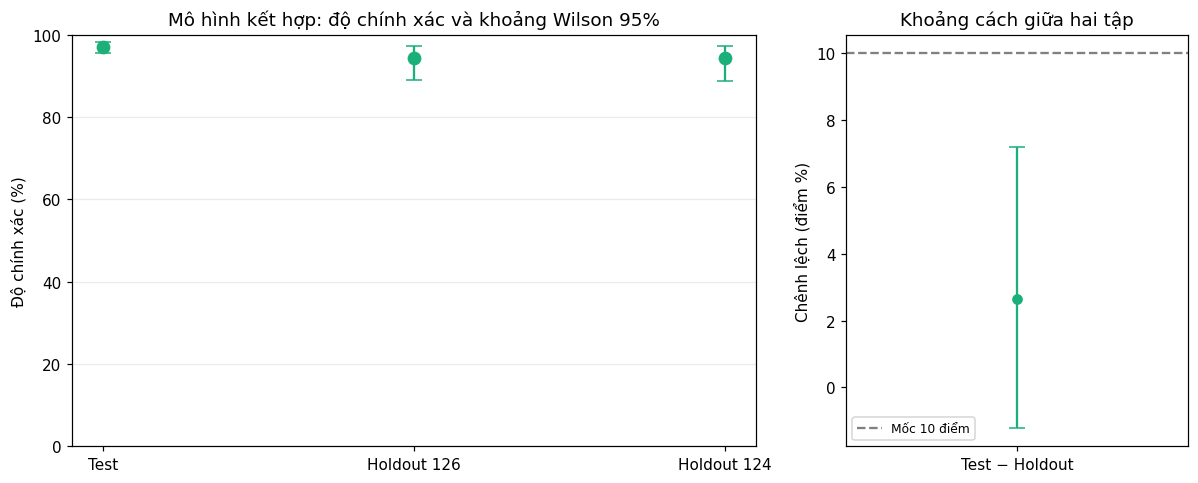

Đã lưu: /content/training_results/current_dataset/EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04/aggregate/figures/combined_only/01_accuracy_and_gap.png


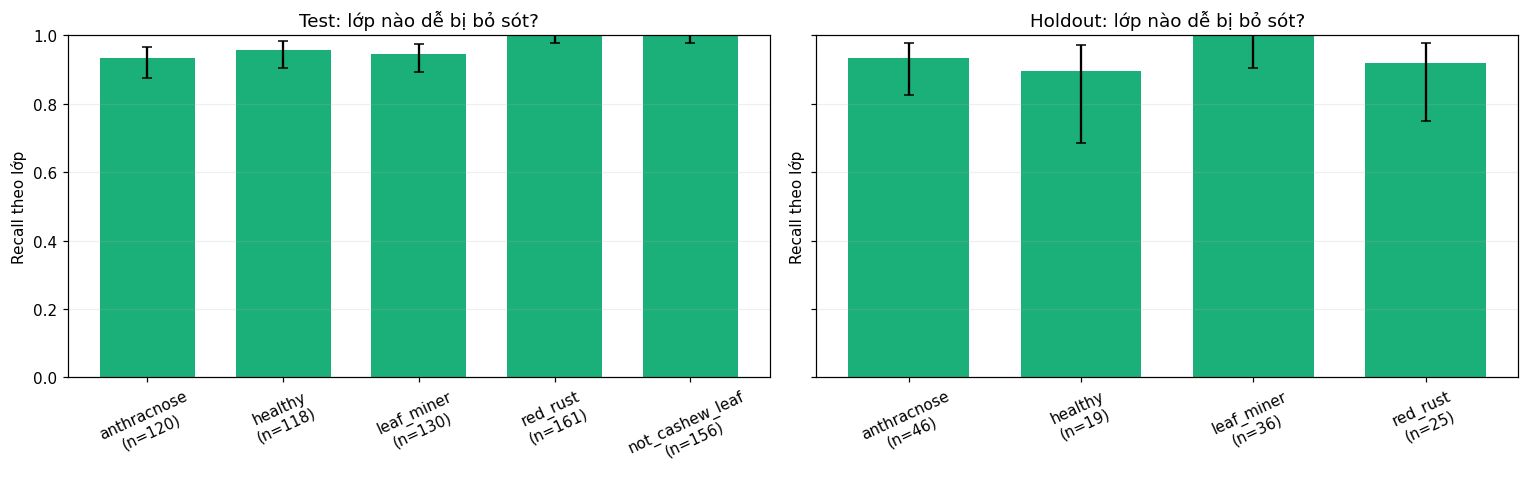

Đã lưu: /content/training_results/current_dataset/EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04/aggregate/figures/combined_only/02_class_recall.png


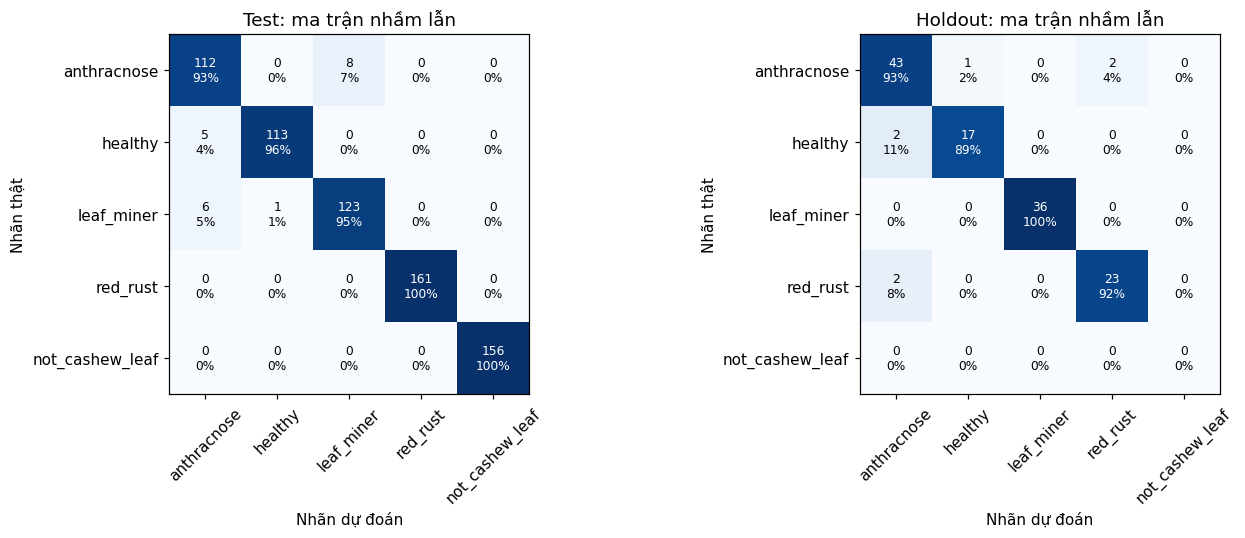

Đã lưu: /content/training_results/current_dataset/EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04/aggregate/figures/combined_only/03_confusion_matrices.png


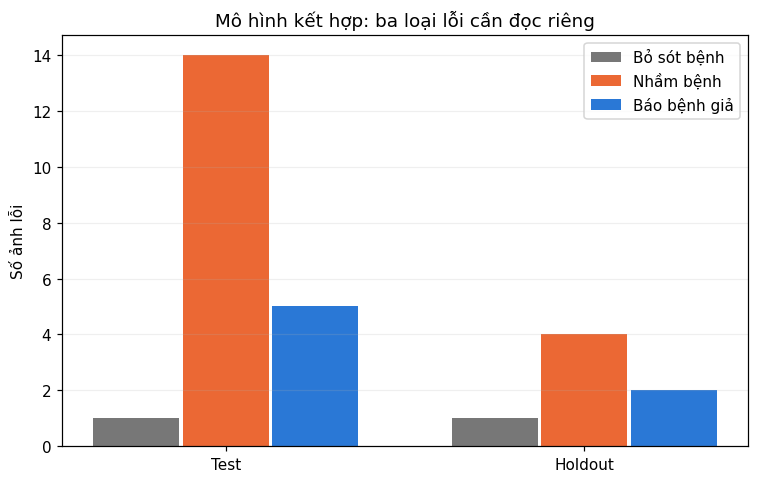

Đã lưu: /content/training_results/current_dataset/EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04/aggregate/figures/combined_only/04_error_types.png


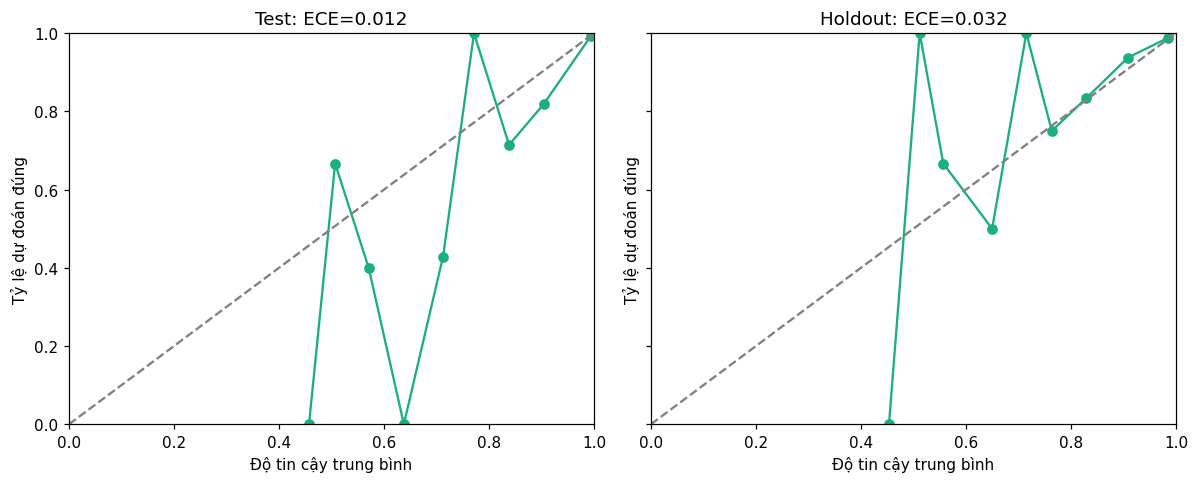

Đã lưu: /content/training_results/current_dataset/EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04/aggregate/figures/combined_only/05_calibration.png


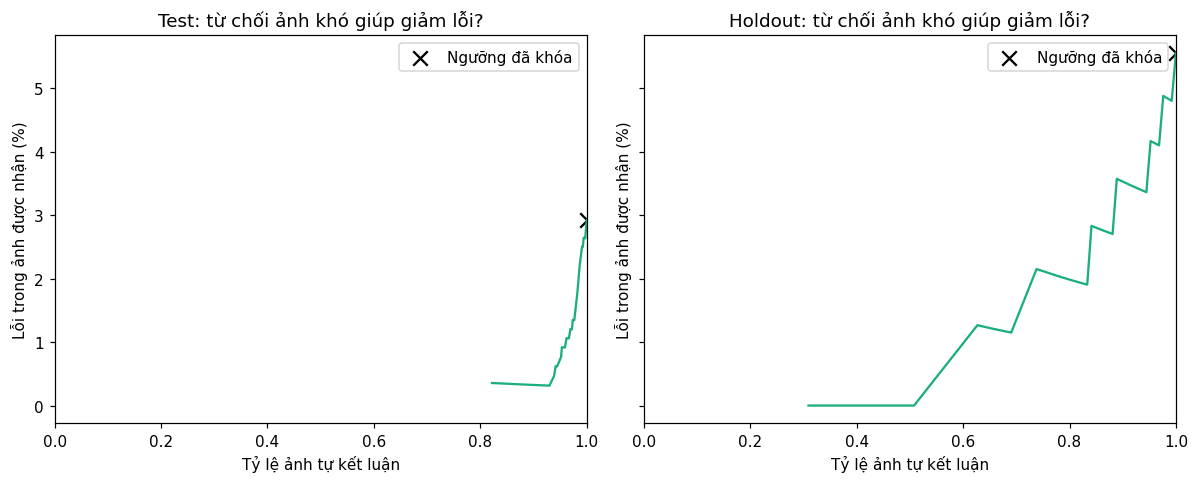

Đã lưu: /content/training_results/current_dataset/EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04/aggregate/figures/combined_only/06_risk_coverage.png


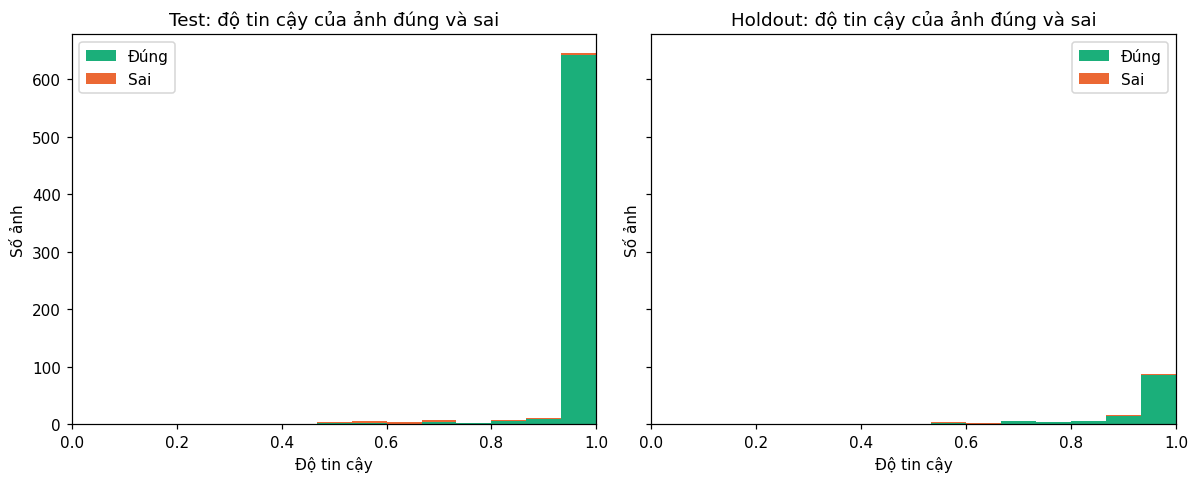

Đã lưu: /content/training_results/current_dataset/EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04/aggregate/figures/combined_only/07_confidence_distribution.png


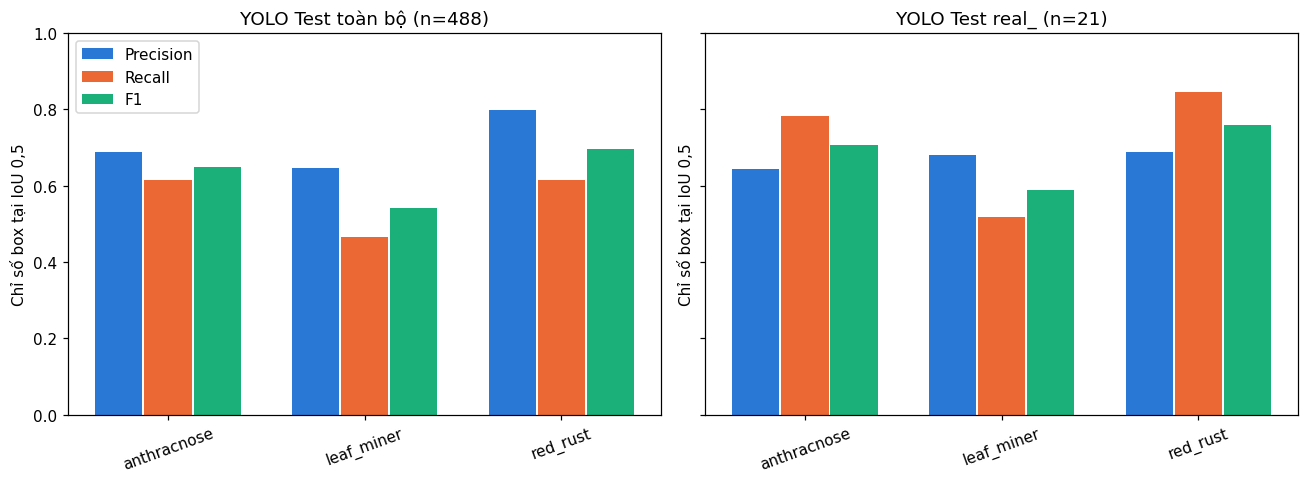

Đã lưu: /content/training_results/current_dataset/EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04/aggregate/figures/combined_only/08_fused_display_localization.png
Chỉ phân tích F3 (DenseNet121 + YOLO). Holdout là đánh giá mô tả, không phải blind benchmark.
Ngưỡng từ chối đã khóa: 0.4262051578949093 | Hình/CSV: /content/training_results/current_dataset/EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04/aggregate/figures/combined_only


In [10]:
# DenseNet121 + YOLO only (F3): statistical figures from already computed results.
# Run after the localization/evaluation cell. This cell never fits or selects a model.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_classes = ["anthracnose", "healthy", "leaf_miner", "red_rust", "not_cashew_leaf"]
_class_index = {name: i for i, name in enumerate(_classes)}
_root = Path(OUT_DIR) if "OUT_DIR" in globals() else None
if _root is None:
    _candidates = [p for p in Path("/content/training_results/current_dataset").glob(
        "EXP-DENSENET121-YOLO*") if (p / "aggregate" / "fusion_results_partB.csv").is_file()]
    if len(_candidates) != 1:
        raise RuntimeError(f"Set OUT_DIR to the intended EXP-035 result folder: {_candidates}")
    _root = _candidates[0]
_aggregate = _root / "aggregate"
_output = _aggregate / "figures" / "combined_only"
_output.mkdir(parents=True, exist_ok=True)

def _read(name):
    path = _aggregate / name
    return pd.read_csv(path) if path.is_file() else pd.DataFrame()

_metrics = _read("fusion_results_partB.csv")
if _metrics.empty or not {"F3", "test", "holdout"}.issubset(
        set(_metrics.get("rule", [])) | set(_metrics.get("split", []))):
    raise RuntimeError("Run Part B/EXP-035 evaluation before this figure cell")
_metrics = _metrics[(_metrics.rule == "F3") &
                    (_metrics.split.isin(["test", "holdout", "holdout_n124"]))].copy()
_errors = _read("error_taxonomy.csv")
_errors = _errors[(_errors.part == "B") & (_errors.rule == "F3")]
_risk = _read("risk_coverage.csv")
_risk = _risk[(_risk.part == "B") & (_risk.rule == "F3")]
_abstention = _read("abstention.csv")
_abstention = _abstention[(_abstention.part == "B") & (_abstention.rule == "F3")]
_localization = _read("localization_test.csv")
_config_path = _aggregate / "frozen_config.json"
_config = json.loads(_config_path.read_text(encoding="utf-8")) if _config_path.is_file() else {}
_threshold = _config.get("abstain_thresholds", {}).get("F3")
_color = "#1baf7a"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10})

def _wilson(correct, total):
    if total == 0:
        return np.nan, np.nan
    z = 1.9599639845
    p = correct / total
    divisor = 1 + z*z/total
    center = (p + z*z/(2*total)) / divisor
    radius = z*np.sqrt((p*(1-p) + z*z/(4*total))/total) / divisor
    return center-radius, center+radius

def _error_magnitudes(mid, low, high):
    """Convert interval bounds to Matplotlib distances, allowing roundoff at 0/1."""
    mid, low, high = np.broadcast_arrays(np.asarray(mid, dtype=float),
                                         np.asarray(low, dtype=float),
                                         np.asarray(high, dtype=float))
    lower = mid - low
    upper = high - mid
    if (not np.isfinite(lower).all() or not np.isfinite(upper).all() or
            np.any(lower < -1e-10) or np.any(upper < -1e-10)):
        raise ValueError(f"Invalid interval bounds: mid={mid}, low={low}, high={high}")
    return np.vstack((np.maximum(0, np.atleast_1d(lower)),
                      np.maximum(0, np.atleast_1d(upper))))

def _save(fig, name):
    fig.tight_layout()
    path = _output / name
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Đã lưu:", path)

def _predictions(split):
    # The live EXP-035 runtime keeps calibrated per-image probabilities.
    if "PART_PREDICTIONS" in globals() and "B" in PART_PREDICTIONS and split in PART_PREDICTIONS["B"]:
        frame, by_rule = PART_PREDICTIONS["B"][split]
        labels, probs = by_rule["F3"]
        result = frame[["evidence_key", "true_label"]].reset_index(drop=True).copy()
        result["predicted_label"] = [_classes[int(i)] for i in labels]
        for i, cls in enumerate(_classes):
            result[f"prob_{cls}"] = probs[:, i]
        return result
    path = _aggregate / f"predictions_{split}_F3.csv"
    return pd.read_csv(path) if path.is_file() else None

_test_pred, _hold_pred = _predictions("test"), _predictions("holdout")
for _split, _frame in (("test", _test_pred), ("holdout", _hold_pred)):
    if _frame is not None:
        if _frame.evidence_key.duplicated().any():
            raise ValueError(f"Duplicate {_split} prediction keys")
        _probs = _frame[[f"prob_{name}" for name in _classes]].to_numpy(dtype=float)
        if not np.isfinite(_probs).all() or not np.allclose(_probs.sum(axis=1), 1, atol=1e-4):
            raise ValueError(f"Invalid {_split} probabilities")
        if not np.array_equal(np.array(_classes)[_probs.argmax(axis=1)],
                              _frame.predicted_label.to_numpy()):
            raise ValueError(f"{_split} labels do not match probabilities")

# Accuracy and Wilson 95% intervals; gap CI uses independent image bootstrap if available.
_acc = _metrics.set_index("split")
_splits = [split for split in ("test", "holdout", "holdout_n124") if split in _acc.index]
_accuracy_rows = []
for _split in _splits:
    _row = _acc.loc[_split]
    _accuracy_rows.append({"split": _split, "n": int(_row.n), "correct": int(_row.correct),
        "accuracy": float(_row.accuracy), "wilson_low": float(_row.wilson_low),
        "wilson_high": float(_row.wilson_high), "ece15": float(_row.ece15)})
_gap = float(_acc.loc["test"].accuracy - _acc.loc["holdout"].accuracy)
_gap_low = _gap_high = np.nan
if _test_pred is not None and _hold_pred is not None:
    _rng = np.random.default_rng(32033)
    _test_ok = (_test_pred.true_label == _test_pred.predicted_label).to_numpy(dtype=float)
    _hold_ok = (_hold_pred.true_label == _hold_pred.predicted_label).to_numpy(dtype=float)
    _ti = _rng.integers(0, len(_test_ok), size=(10000, len(_test_ok)))
    _hi = _rng.integers(0, len(_hold_ok), size=(10000, len(_hold_ok)))
    _distribution = _test_ok[_ti].mean(axis=1) - _hold_ok[_hi].mean(axis=1)
    _gap_low, _gap_high = np.quantile(_distribution, [.025, .975])
pd.DataFrame(_accuracy_rows).to_csv(_output / "accuracy_wilson.csv", index=False)
pd.DataFrame([{"test_minus_holdout": _gap, "bootstrap_low": _gap_low,
               "bootstrap_high": _gap_high, "resamples": 10000 if np.isfinite(_gap_low) else 0}]).to_csv(
                   _output / "test_holdout_gap.csv", index=False)
fig, (ax, gap_ax) = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [2, 1]})
for i, record in enumerate(_accuracy_rows):
    mid = 100 * record["accuracy"]
    ax.errorbar(i, mid, yerr=_error_magnitudes(mid, 100*record["wilson_low"],
                                                100*record["wilson_high"]),
                fmt="o", capsize=5, color=_color, markersize=8)
ax.set(xticks=range(len(_splits)), xticklabels=["Test", "Holdout 126", "Holdout 124"][:len(_splits)],
       ylim=(0, 100), ylabel="Độ chính xác (%)",
       title="Mô hình kết hợp: độ chính xác và khoảng Wilson 95%")
ax.grid(axis="y", alpha=.25)
if np.isfinite(_gap_low):
    gap_ax.errorbar(0, 100*_gap, yerr=_error_magnitudes(100*_gap, 100*_gap_low,
                                                          100*_gap_high),
                    fmt="o", capsize=5, color=_color)
else:
    gap_ax.scatter(0, 100*_gap, color=_color)
    gap_ax.text(.5, .05, "Không có xác suất từng ảnh\nđể tính khoảng bootstrap",
                transform=gap_ax.transAxes, ha="center", fontsize=8)
gap_ax.axhline(10, color="grey", ls="--", label="Mốc 10 điểm")
gap_ax.set(xlim=(-.5, .5), xticks=[0], xticklabels=["Test − Holdout"],
           ylabel="Chênh lệch (điểm %)", title="Khoảng cách giữa hai tập")
gap_ax.legend(fontsize=8)
_save(fig, "01_accuracy_and_gap.png")

# Class recall uses the row support of each saved F3 confusion matrix.
_class_rows = []
for _split in ("test", "holdout"):
    _cm = pd.read_csv(_aggregate / f"confusion_B_{_split}_F3.csv", index_col=0)
    _cm = _cm.reindex(index=_classes, columns=_classes, fill_value=0)
    for _class in _classes:
        _support = int(_cm.loc[_class].sum())
        if _support:
            _correct = int(_cm.loc[_class, _class])
            _low, _high = _wilson(_correct, _support)
            _class_rows.append({"split": _split, "class": _class, "support": _support,
                "correct": _correct, "recall": _correct/_support,
                "wilson_low": _low, "wilson_high": _high})
_class_table = pd.DataFrame(_class_rows)
_class_table.to_csv(_output / "class_recall_wilson.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, _split in zip(axes, ("test", "holdout")):
    _rows = _class_table[_class_table.split == _split]
    x = np.arange(len(_rows))
    ax.bar(x, _rows.recall.to_numpy(), color=_color, width=.7)
    midpoint = _rows.recall.to_numpy(dtype=float)
    ax.errorbar(x, midpoint,
                yerr=_error_magnitudes(midpoint,
                                       _rows.wilson_low.to_numpy(dtype=float),
                                       _rows.wilson_high.to_numpy(dtype=float)),
                fmt="none", ecolor="black", capsize=3)
    ax.set(xticks=x, xticklabels=[f"{r['class']}\n(n={r['support']})" for _, r in _rows.iterrows()],
           ylim=(0, 1), ylabel="Recall theo lớp", title=f"{_split.title()}: lớp nào dễ bị bỏ sót?")
    ax.tick_params(axis="x", labelrotation=25)
    ax.grid(axis="y", alpha=.2)
_save(fig, "02_class_recall.png")

# Confusion matrices show counts and row percentages on a shared 0–100% scale.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, _split in zip(axes, ("test", "holdout")):
    _cm = pd.read_csv(_aggregate / f"confusion_B_{_split}_F3.csv", index_col=0)
    _cm = _cm.reindex(index=_classes, columns=_classes, fill_value=0)
    counts = _cm.to_numpy(dtype=int)
    support = counts.sum(axis=1, keepdims=True)
    frac = np.divide(counts, support, out=np.zeros_like(counts, dtype=float), where=support > 0)
    ax.imshow(frac, cmap="Blues", vmin=0, vmax=1)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{counts[i,j]}\n{frac[i,j]:.0%}", ha="center", va="center",
                    fontsize=8, color="white" if frac[i,j] > .55 else "black")
    ax.set(xticks=range(5), xticklabels=_classes, yticks=range(5), yticklabels=_classes,
           xlabel="Nhãn dự đoán", ylabel="Nhãn thật", title=f"{_split.title()}: ma trận nhầm lẫn")
    ax.tick_params(axis="x", labelrotation=45)
_save(fig, "03_confusion_matrices.png")

_error_rows = _errors[_errors.split.isin(["test", "holdout"])][
    ["split", "missed_disease", "wrong_disease_type", "false_alarm"]].copy()
_error_rows.to_csv(_output / "error_types.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 4.5))
_error_names = [("missed_disease", "Bỏ sót bệnh", "#777777"),
                ("wrong_disease_type", "Nhầm bệnh", "#eb6834"),
                ("false_alarm", "Báo bệnh giả", "#2a78d6")]
for i, (_field, _label, _shade) in enumerate(_error_names):
    ax.bar(np.arange(2) + (i-1)*.25,
           [int(_error_rows[_error_rows.split == s].iloc[0][_field]) for s in ("test", "holdout")],
           width=.24, label=_label, color=_shade)
ax.set(xticks=[0, 1], xticklabels=["Test", "Holdout"], ylabel="Số ảnh lỗi",
       title="Mô hình kết hợp: ba loại lỗi cần đọc riêng")
ax.legend()
ax.grid(axis="y", alpha=.2)
_save(fig, "04_error_types.png")

# A reliability diagram needs per-image probabilities; ECE is still shown when absent.
_bin_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, _split, _pred in zip(axes, ("test", "holdout"), (_test_pred, _hold_pred)):
    _ece = float(_acc.loc[_split].ece15)
    if _pred is not None:
        probs = _pred[[f"prob_{name}" for name in _classes]].to_numpy(dtype=float)
        confidence = probs.max(axis=1)
        correct = (_pred.true_label == _pred.predicted_label).to_numpy()
        x, y = [], []
        for b in range(15):
            low, high = b/15, (b+1)/15
            chosen = (confidence >= low) & ((confidence <= high) if b == 14 else (confidence < high))
            if chosen.any():
                mean_conf, observed = float(confidence[chosen].mean()), float(correct[chosen].mean())
                x.append(mean_conf)
                y.append(observed)
                _bin_rows.append({"split": _split, "bin": b, "n": int(chosen.sum()),
                                  "mean_confidence": mean_conf, "observed_accuracy": observed})
        ax.plot(x, y, "o-", color=_color)
    else:
        ax.text(.5, .5, "Thiếu xác suất từng ảnh\nchỉ có ECE tổng hợp",
                transform=ax.transAxes, ha="center", va="center")
    ax.plot([0, 1], [0, 1], "--", color="grey")
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Độ tin cậy trung bình",
           ylabel="Tỷ lệ dự đoán đúng", title=f"{_split.title()}: ECE={_ece:.3f}")
pd.DataFrame(_bin_rows, columns=["split", "bin", "n", "mean_confidence",
    "observed_accuracy"]).to_csv(_output / "reliability_bins.csv", index=False)
_save(fig, "05_calibration.png")

_risk_rows = _risk[_risk.split.isin(["test", "holdout"])][
    ["split", "threshold", "coverage", "risk"]].copy()
_risk_rows.to_csv(_output / "risk_coverage.csv", index=False)
_abstention_rows = _abstention[_abstention.split.isin(["test", "holdout"])][
    ["split", "threshold", "coverage", "selective_accuracy", "referred_to_expert"]].copy()
_abstention_rows.to_csv(_output / "abstention.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, _split in zip(axes, ("test", "holdout")):
    view = _risk_rows[_risk_rows.split == _split].dropna(subset=["risk"])
    ax.plot(view.coverage, 100*view.risk, color=_color)
    point = _abstention_rows[_abstention_rows.split == _split]
    if not point.empty and np.isfinite(point.iloc[0].selective_accuracy):
        ax.scatter(point.iloc[0].coverage, 100*(1-point.iloc[0].selective_accuracy),
                   marker="x", color="black", s=90, label="Ngưỡng đã khóa")
    ax.set(xlim=(0, 1), xlabel="Tỷ lệ ảnh tự kết luận",
           ylabel="Lỗi trong ảnh được nhận (%)",
           title=f"{_split.title()}: từ chối ảnh khó giúp giảm lỗi?")
    ax.legend()
_save(fig, "06_risk_coverage.png")

if _test_pred is not None and _hold_pred is not None:
    _confidence_rows = []
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
    for ax, _split, _pred in zip(axes, ("test", "holdout"), (_test_pred, _hold_pred)):
        probs = _pred[[f"prob_{name}" for name in _classes]].to_numpy(dtype=float)
        confidence = probs.max(axis=1)
        correct = (_pred.true_label == _pred.predicted_label).to_numpy()
        _confidence_rows.extend({"split": _split, "evidence_key": key,
            "confidence": float(q), "correct": bool(ok)}
            for key, q, ok in zip(_pred.evidence_key, confidence, correct))
        ax.hist([confidence[correct], confidence[~correct]], bins=np.linspace(0, 1, 16),
                stacked=True, color=[_color, "#eb6834"], label=["Đúng", "Sai"])
        ax.set(xlim=(0, 1), xlabel="Độ tin cậy", ylabel="Số ảnh",
               title=f"{_split.title()}: độ tin cậy của ảnh đúng và sai")
        ax.legend()
    pd.DataFrame(_confidence_rows).to_csv(_output / "confidence_by_image.csv", index=False)
    _save(fig, "07_confidence_distribution.png")

_selected = globals().get("SELECTED_DEFAULT")
if _selected is None and (_aggregate / "combined_summary.json").is_file():
    _selected = "F3"  # EXP-035 summary declares the combined method.
if _selected == "F3" and not _localization.empty and "mode" in _localization.columns:
    _loc = _localization[(_localization["mode"] == "fused_display") &
                         (_localization["subset"].isin(["all", "real_"]))].copy()
    if not _loc.empty:
        _loc.to_csv(_output / "fused_display_localization.csv", index=False)
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
        for ax, subset in zip(axes, ("all", "real_")):
            view = _loc[_loc["subset"] == subset].set_index("class")
            names = [cls for cls in ("anthracnose", "leaf_miner", "red_rust") if cls in view.index]
            x = np.arange(len(names))
            for i, (field, label, shade) in enumerate((
                    ("precision50", "Precision", "#2a78d6"),
                    ("recall50", "Recall", "#eb6834"),
                    ("f1_50", "F1", "#1baf7a"))):
                ax.bar(x + (i-1)*.25, view.loc[names, field].to_numpy(dtype=float),
                       width=.24, label=label, color=shade)
            count = int(view.images.iloc[0]) if len(view) else 0
            ax.set(xticks=x, xticklabels=names, ylim=(0, 1),
                   ylabel="Chỉ số box tại IoU 0,5",
                   title=f"YOLO Test {'real_' if subset == 'real_' else 'toàn bộ'} (n={count})")
            ax.tick_params(axis="x", labelrotation=20)
        axes[0].legend()
        _save(fig, "08_fused_display_localization.png")
else:
    print("Bỏ qua hình định vị: bảng fused_display hiện có không được xác nhận là của F3.")

print("Chỉ phân tích F3 (DenseNet121 + YOLO). Holdout là đánh giá mô tả, không phải blind benchmark.")
print("Ngưỡng từ chối đã khóa:", _threshold, "| Hình/CSV:", _output)


In [11]:
PIPELINE_MODULE_SOURCE = '"""Standalone EXP-035 Cashew + YOLO pipeline. Generated from notebook source."""\nimport json\nfrom pathlib import Path\nimport joblib\nimport numpy as np\nimport tensorflow as tf\nfrom tensorflow import keras\nfrom tensorflow.keras import layers\nfrom PIL import Image, ImageOps\n\n@keras.utils.register_keras_serializable(package="exp029", name="RandomHSVJitter")\nclass RandomHSVJitter(layers.Layer):\n    """Per-image saturation scaling, hue shift and random grayscale.\n\n    Active only when training=True so the Validation/Test/holdout path stays\n    a pure identity, which the smoke test below asserts.\n    """\n\n    def __init__(self, saturation_range=(0.6, 1.4), hue_delta=0.03,\n                 grayscale_probability=0.10, value_range=(0.0, 255.0),\n                 seed=None, **kwargs):\n        super().__init__(**kwargs)\n        if not (0.0 < saturation_range[0] <= 1.0 <= saturation_range[1]):\n            raise ValueError("saturation_range must bracket 1.0")\n        if not 0.0 <= hue_delta <= 0.5:\n            raise ValueError("hue_delta must be within [0, 0.5]")\n        if not 0.0 <= grayscale_probability <= 1.0:\n            raise ValueError("grayscale_probability must be within [0, 1]")\n        self.saturation_range = tuple(float(v) for v in saturation_range)\n        self.hue_delta = float(hue_delta)\n        self.grayscale_probability = float(grayscale_probability)\n        self.value_range = tuple(float(v) for v in value_range)\n        self.seed = seed\n        self.seed_generator = keras.random.SeedGenerator(seed)\n\n    def call(self, inputs, training=False):\n        if not training:\n            return inputs\n        low, high = self.value_range\n        span = high - low\n        normalized = tf.clip_by_value((inputs - low) / span, 0.0, 1.0)\n        batch = tf.shape(normalized)[0]\n        saturation = keras.random.uniform(\n            (batch, 1, 1), self.saturation_range[0], self.saturation_range[1],\n            seed=self.seed_generator)\n        grayscale_draw = keras.random.uniform(\n            (batch, 1, 1), 0.0, 1.0, seed=self.seed_generator)\n        saturation = tf.where(grayscale_draw < self.grayscale_probability,\n                              tf.zeros_like(saturation), saturation)\n        hue_shift = keras.random.uniform(\n            (batch, 1, 1), -self.hue_delta, self.hue_delta, seed=self.seed_generator)\n        hsv = tf.image.rgb_to_hsv(normalized)\n        hue = tf.math.floormod(hsv[..., 0] + hue_shift, 1.0)\n        sat = tf.clip_by_value(hsv[..., 1] * saturation, 0.0, 1.0)\n        value = hsv[..., 2]\n        converted = tf.image.hsv_to_rgb(tf.stack([hue, sat, value], axis=-1))\n        return tf.clip_by_value(converted * span + low, low, high)\n\n    def compute_output_shape(self, input_shape):\n        return input_shape\n\n    def get_config(self):\n        config = super().get_config()\n        config.update({"saturation_range": list(self.saturation_range),\n                       "hue_delta": self.hue_delta,\n                       "grayscale_probability": self.grayscale_probability,\n                       "value_range": list(self.value_range),\n                       "seed": self.seed})\n        return config\n\n\n\nclass CashewPipeline:\n    def __init__(self,bundle_dir):\n        self.bundle_dir=Path(bundle_dir)\n        self.config=json.loads((self.bundle_dir/"frozen_config.json").read_text(encoding="utf-8"))\n        self.classes=self.config["classes"]\n        self.detector_classes=self.config["detector_classes"]\n        self.models=[keras.models.load_model(self.bundle_dir/f"seed_{seed}"/"deployment_model.keras")\n                     for seed in self.config["seeds"]]\n        self.stackers=joblib.load(self.bundle_dir/"stacker.joblib")\n        self.rule=json.loads((self.bundle_dir/"decision.json").read_text(encoding="utf-8"))["selected_default_rule"]\n        if self.config.get("dry_run_stub_detector"):\n            self.detector=None\n        else:\n            from ultralytics import YOLO\n            self.detector=YOLO(str(self.bundle_dir/"best.pt"))\n\n    @staticmethod\n    def _iou(a,b):\n        x1,y1,x2,y2=max(a[0],b[0]),max(a[1],b[1]),min(a[2],b[2]),min(a[3],b[3])\n        inter=max(0,x2-x1)*max(0,y2-y1)\n        aa=max(0,a[2]-a[0])*max(0,a[3]-a[1]);bb=max(0,b[2]-b[0])*max(0,b[3]-b[1])\n        return inter/(aa+bb-inter) if aa+bb>inter else 0.0\n\n    def _boxes(self,image,path):\n        height,width=image.shape[:2]\n        if self.detector is None:\n            if path is None or np.std(image)==0:\n                return [],(height,width)\n            name=Path(path).parent.name\n            cls=(self.detector_classes.index(name) if name in self.detector_classes else 0)\n            return ([{"cls":self.detector_classes[cls],"conf":.75,\n                     "xyxy":[width*.3,height*.3,width*.7,height*.7]}],(height,width))\n        source=str(path) if path is not None else image\n        result=self.detector.predict(source,conf=.05,iou=.7,imgsz=640,rect=False,verbose=False)[0]\n        boxes=[{"cls":self.detector_classes[int(c)],"conf":float(q),"xyxy":xy.tolist()}\n               for c,q,xy in zip(result.boxes.cls.cpu().numpy(),result.boxes.conf.cpu().numpy(),\n                                 result.boxes.xyxy.cpu().numpy())]\n        return boxes,tuple(result.orig_shape)\n\n    def predict(self,image_path_or_array):\n        path=Path(image_path_or_array) if isinstance(image_path_or_array,(str,Path)) else None\n        if path is not None:\n            # Match make_dataset: tf.io.decode_image does not apply PIL EXIF transpose.\n            image=tf.io.decode_image(tf.io.read_file(str(path)),channels=3,\n                                     expand_animations=False).numpy()\n        else:\n            image=np.asarray(image_path_or_array)\n            if image.ndim==2: image=np.repeat(image[...,None],3,axis=2)\n            elif image.ndim==3 and image.shape[2]==1: image=np.repeat(image,3,axis=2)\n            elif image.ndim==3 and image.shape[2]==4: image=image[:,:,:3]\n            if image.ndim!=3 or image.shape[2]!=3: raise ValueError("Expected RGB or grayscale image")\n            image=np.clip(image,0,255).astype(np.uint8)\n        resized=tf.image.resize(tf.cast(image,tf.float32),(256,256)).numpy()[None,...]\n        p=np.mean([model.predict(resized,verbose=0)[0] for model in self.models],axis=0)\n        boxes,(h,w)=self._boxes(image,path)\n        evidence={"max_conf":{},"n_boxes":{},"area_frac":{}}\n        for cls in self.detector_classes:\n            subset=[b for b in boxes if b["cls"]==cls]\n            evidence["max_conf"][cls]=max([b["conf"] for b in subset],default=0.0)\n            evidence["n_boxes"][cls]=len(subset)\n            evidence["area_frac"][cls]=min(sum((b["xyxy"][2]-b["xyxy"][0])*\n                 (b["xyxy"][3]-b["xyxy"][1]) for b in subset)/(w*h),1.0)\n        feature=np.array(list(p)+[evidence[prefix][cls] for prefix in\n                     ("max_conf","n_boxes","area_frac") for cls in self.detector_classes],dtype=float)\n        assert self.rule == "F3"\n        model=self.stackers["F3"]\n        fitted=model.predict_proba(feature[None,:])[0]\n        p=np.zeros(len(self.classes));p[model[-1].classes_]=fitted\n        temperature=self.config["temperature"][self.rule]\n        p=np.clip(p,1e-9,1)**(1/temperature);p=p/p.sum()\n        order=np.argsort(-p);label=self.classes[order[0]]\n        abstain=bool(p[order[0]]<self.config["abstain_thresholds"][self.rule])\n        shown=[]\n        if not abstain and label in self.detector_classes:\n            for box in sorted((b for b in boxes if b["conf"]>=self.config["box_conf"]),\n                              key=lambda b:-b["conf"]):\n                if all(box["cls"]!=old["cls"] or self._iou(box["xyxy"],old["xyxy"])<=.5 for old in shown):\n                    shown.append(box)\n                if len(shown)>=60: break\n        return {"label":label,"confidence":float(p[order[0]]),\n                "top2":[(self.classes[i],float(p[i])) for i in order[:2]],\n                "abstain":abstain,"probs":{name:float(p[i]) for i,name in enumerate(self.classes)},\n                "evidence":evidence,"boxes":shown,"rule":self.rule,"version":"EXP-035",\n                "action":"cần chuyên gia kiểm tra" if abstain else ("không phát hiện bệnh" if label in ("healthy","not_cashew_leaf") else "predict")}\n'
# Export and hard consistency check. The module source is embedded by the build script.
if RUN_PART_B:
    module_path=OUT_DIR/"cashew_pipeline.py"
    module_path.write_text(PIPELINE_MODULE_SOURCE,encoding="utf-8")
    import importlib.util
    spec=importlib.util.spec_from_file_location("cashew_pipeline",module_path)
    pipeline_module=importlib.util.module_from_spec(spec);sys.modules[spec.name]=pipeline_module
    spec.loader.exec_module(pipeline_module)
    bundle=OUT_DIR/"pipeline_bundle"
    bundle.mkdir(exist_ok=True)
    shutil.copy2(module_path,bundle/"cashew_pipeline.py")
    for seed in SEEDS:
        target=bundle/f"seed_{seed}"
        target.mkdir(exist_ok=True)
        shutil.copy2(OUT_DIR/f"seed_{seed}"/"deployment_model.keras",target/"deployment_model.keras")
    if not DRY_RUN:
        shutil.copy2(DETECTOR_WEIGHTS_PATH,bundle/"best.pt")
        assert file_sha256(bundle/"best.pt")==DETECTOR_WEIGHTS_SHA256
    shutil.copy2(AGGREGATE/"stacker.joblib",bundle/"stacker.joblib")
    shutil.copy2(AGGREGATE/"frozen_config.json",bundle/"frozen_config.json")
    write_json(bundle/"decision.json",{"selected_default_rule":SELECTED_DEFAULT,
        "rule":"Single combined model frozen before Test and Holdout"})
    # The dry-run detector stub is explicit and never enters a real bundle.
    if DRY_RUN:
        frozen=json.loads((bundle/"frozen_config.json").read_text(encoding="utf-8"))
        frozen["dry_run_stub_detector"]=True
        write_json(bundle/"frozen_config.json",frozen)
    files=[p for p in bundle.rglob("*") if p.is_file()]
    pd.DataFrame([{"path":p.relative_to(bundle).as_posix(),"bytes":p.stat().st_size,
                   "sha256":file_sha256(p)} for p in files]).to_csv(bundle/"artifact_sha256.csv",index=False)
    pipeline=pipeline_module.CashewPipeline(bundle)
    hold_frame,hold_predictions=PART_PREDICTIONS["B"]["holdout"]
    selected_rule=SELECTED_DEFAULT
    fixed_keys=sorted(hold_frame.evidence_key)[:min(20,len(hold_frame))]
    for key in fixed_keys:
        path=INVENTORY["holdout"].set_index("evidence_key").loc[key,"path"]
        actual=pipeline.predict(path)
        one=hold_frame[hold_frame.evidence_key==key]
        expected=apply_temperature(rule_probs(one,selected_rule,modelsB),
                                   configB["temperature"][selected_rule])[0]
        assert actual["label"]==CLASSES[int(np.argmax(expected))]
        if not np.allclose([actual["probs"][c] for c in CLASSES],expected,atol=1e-4):
            dense_batch=one[PROB_COLUMNS].to_numpy(dtype=float)[0]
            raw=tf.io.decode_image(tf.io.read_file(str(path)),channels=3,
                                   expand_animations=False)
            resized=tf.image.resize(tf.cast(raw,tf.float32),(IMG_SIZE,IMG_SIZE)).numpy()[None,...]
            dense_single=np.mean([model.predict(resized,verbose=0)[0] for model in pipeline.models],axis=0)
            evidence_batch={name:{cls:float(one.iloc[0][f"{name}_{cls}"])
                                  for cls in DETECTOR_CLASSES}
                            for name in ("max_conf","n_boxes","area_frac")}
            raise AssertionError(
                f"Pipeline probabilities differ for {key}; "
                f"dense_max_abs={np.max(np.abs(dense_single-dense_batch)):.6g}; "
                f"dense_batch={dense_batch}; dense_single={dense_single}; "
                f"evidence_batch={evidence_batch}; evidence_single={actual['evidence']}; "
                f"final_batch={expected}; final_single={[actual['probs'][c] for c in CLASSES]}")
        stored=BOX_FRAMES["holdout"][BOX_FRAMES["holdout"].evidence_key==key]
        expected_boxes=display_boxes(stored,BOX_CONF,actual["label"],actual["abstain"],draw_cap=60)
        assert len(actual["boxes"])==len(expected_boxes)
        for left,right in zip(actual["boxes"],expected_boxes):
            assert left["cls"]==right["cls"] and abs(left["conf"]-right["conf"])<1e-4
            assert np.allclose(left["xyxy"],right["xyxy"],atol=1e-4)
    old_detector=pipeline.detector
    pipeline.detector=None
    assert pipeline.predict(np.zeros((48,48,3),dtype=np.uint8))["boxes"]==[]
    pipeline.detector=old_detector
    assert isinstance(pipeline.predict(np.full((48,48),128,dtype=np.uint8))["label"],str)
    write_json(AGGREGATE/"pipeline_consistency.json",{"status":"PASS",
        "holdout_images":len(fixed_keys),"probability_atol":1e-4,
        "same_boxes":True,"no_detection_and_grayscale":True})
    print("Pipeline consistency PASS",len(fixed_keys),"Holdout images + no-detection + grayscale")



Pipeline consistency PASS 20 Holdout images + no-detection + grayscale


## Báo cáo mô hình kết hợp

Các bảng, biểu đồ và ảnh dưới đây chỉ mô tả DenseNet121 + YOLO26s.


### Huấn luyện phần DenseNet trong pipeline kết hợp

| seed | stage | selected | epochs | val_loss | seconds | model_sha256 |
|---|---|---|---|---|---|---|
| 42 | stage1 | False | 12 | 0.192 | 102.6738 | feb05191bddd7e2b29f88294bff215237cbbd5738067e6cc9c0b5ad9d52b20ef |
| 42 | stage2 | True | 30 | 0.0764 | 225.9075 | feb05191bddd7e2b29f88294bff215237cbbd5738067e6cc9c0b5ad9d52b20ef |
| 123 | stage1 | False | 12 | 0.2022 | 74.3091 | fd8350c417fc75d5dbedabb8be45c5e1f1575ccb5a2667ed9a68610c62717183 |
| 123 | stage2 | True | 30 | 0.0745 | 218.1558 | fd8350c417fc75d5dbedabb8be45c5e1f1575ccb5a2667ed9a68610c62717183 |
| 2026 | stage1 | False | 12 | 0.196 | 74.2054 | c24aefe0befbb14dfae07f713c7a6f1774caf2f9910e0608c4bf8f7a2d2559f3 |
| 2026 | stage2 | True | 30 | 0.0801 | 218.2836 | c24aefe0befbb14dfae07f713c7a6f1774caf2f9910e0608c4bf8f7a2d2559f3 |
| 3407 | stage1 | False | 12 | 0.1997 | 72.9629 | 3528277898238b5ffd456161c665adfef4699dcd19ff9b2632b5f08fda7f608a |
| 3407 | stage2 | True | 30 | 0.0678 | 219.1819 | 3528277898238b5ffd456161c665adfef4699dcd19ff9b2632b5f08fda7f608a |
| 7777 | stage1 | False | 12 | 0.1981 | 74.7494 | 042b4e65e73d3fc5b593276d219edd3215f0e8dc210c35d327d0336f3dc86409 |
| 7777 | stage2 | True | 21 | 0.0816 | 153.7198 | 042b4e65e73d3fc5b593276d219edd3215f0e8dc210c35d327d0336f3dc86409 |

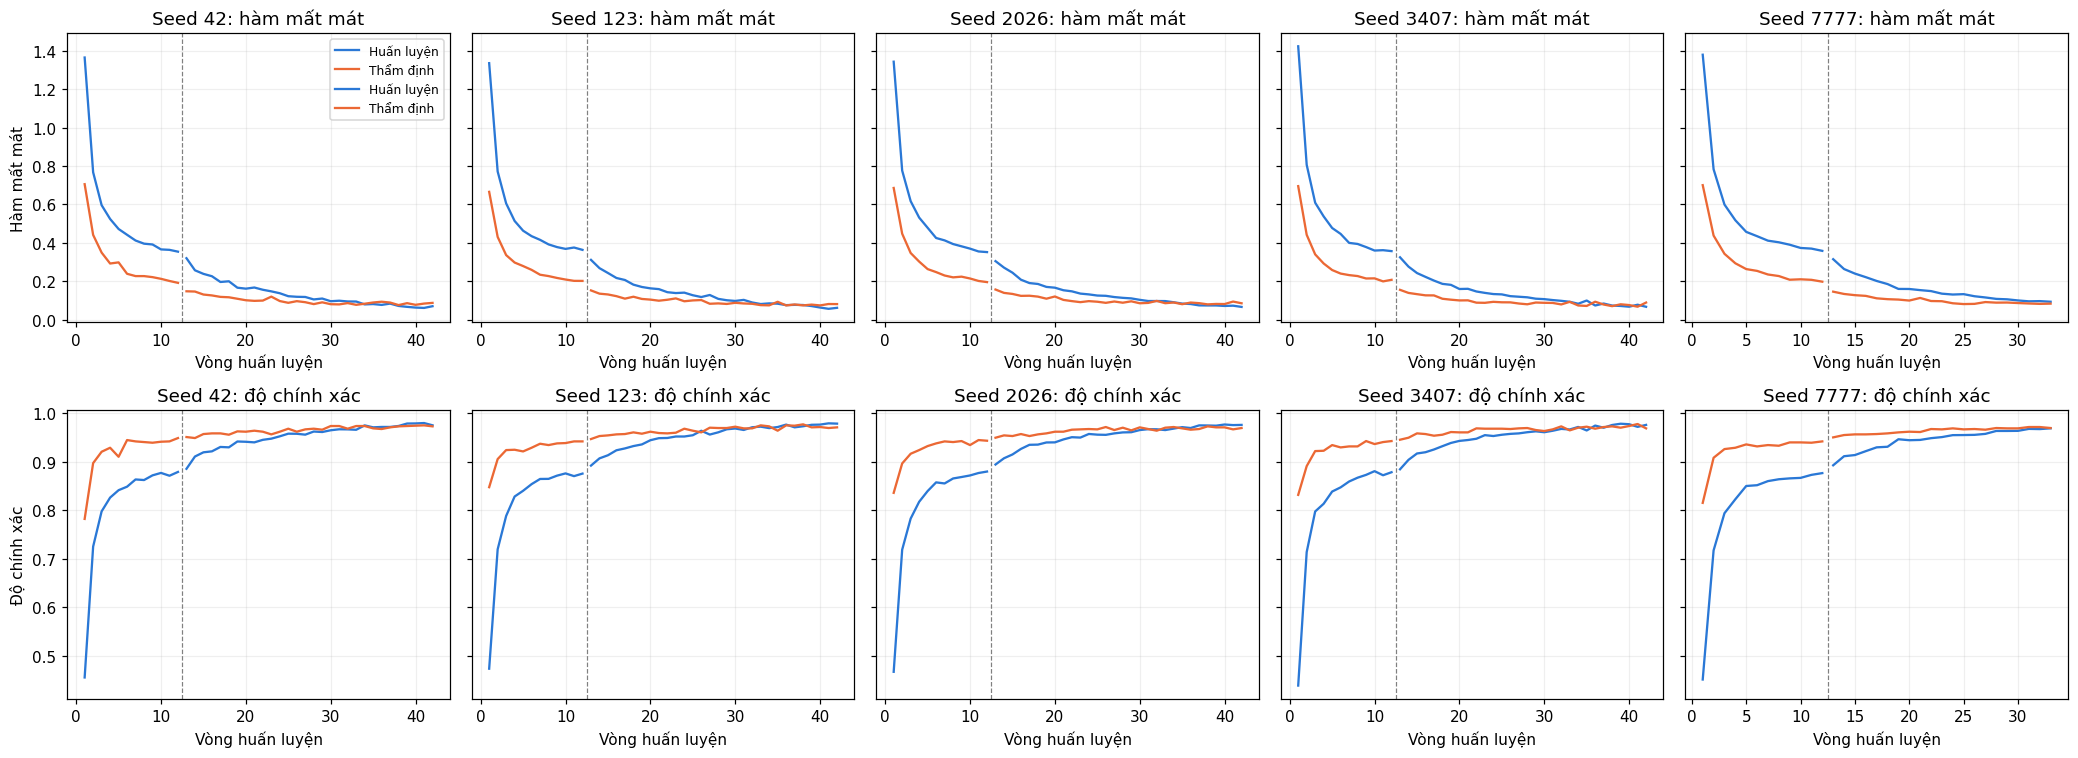

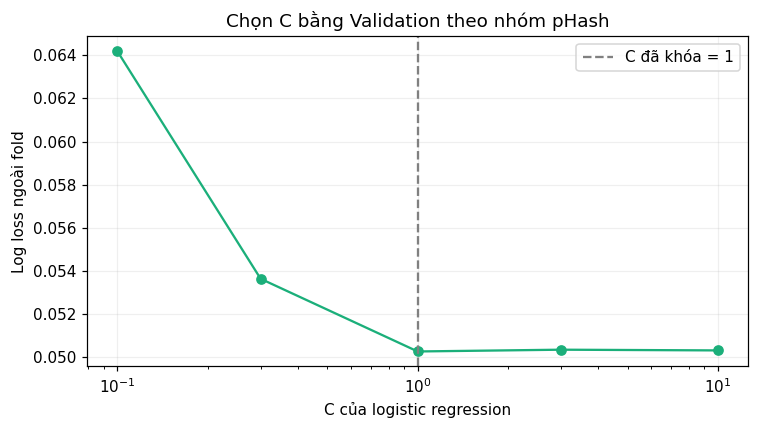

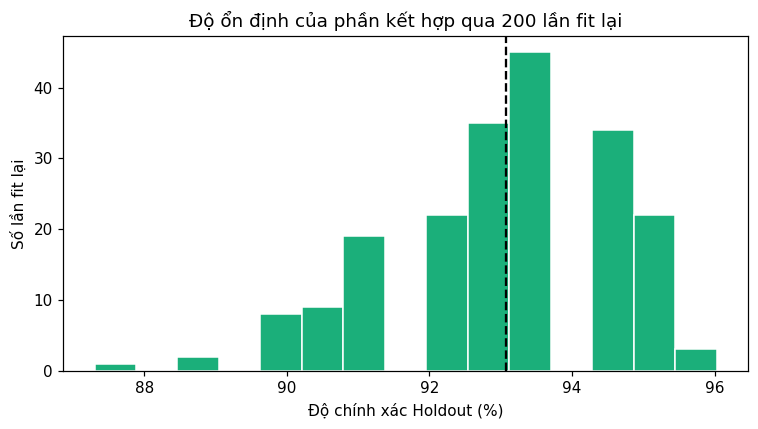

### Kết quả cuối của DenseNet121 + YOLO

| split | n | correct | accuracy | wilson_low | wilson_high | macro_f1 | top2_accuracy | ece15 | recall_anthracnose | recall_healthy | recall_leaf_miner | recall_red_rust | recall_not_cashew_leaf | missed_disease | wrong_disease_type | false_alarm | threshold | coverage | selective_accuracy | referred_to_expert |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| validation_clean | 1361 | 1343 | 0.9868 | 0.9792 | 0.9916 | 0.9862 | 0.9985 | 0.0052 | 0.9652 | 0.9906 | 0.9766 | 1.0 | 1.0 | 5 | 11 | 2 | 0.4262 | 1.0 | 0.9868 | 0 |
| test | 685 | 665 | 0.9708 | 0.9553 | 0.981 | 0.9677 | 0.9985 | 0.0124 | 0.9333 | 0.9576 | 0.9462 | 1.0 | 1.0 | 1 | 14 | 5 | 0.4262 | 1.0 | 0.9708 | 0 |
| holdout | 126 | 119 | 0.9444 | 0.8898 | 0.9728 | 0.7527 | 0.9841 | 0.0323 | 0.9348 | 0.8947 | 1.0 | 0.92 | nan | 1 | 4 | 2 | 0.4262 | 1.0 | 0.9444 | 0 |
| holdout_n124 | 124 | 117 | 0.9435 | 0.8881 | 0.9724 | 0.7508 | 0.9839 | 0.0343 | 0.9348 | 0.8824 | 1.0 | 0.92 | nan | 1 | 4 | 2 | 0.4262 | 1.0 | 0.9435 | 0 |

Validation là dự đoán ngoài fold theo nhóm pHash. Holdout 09 đã được xem trước, chỉ là đánh giá mô tả.

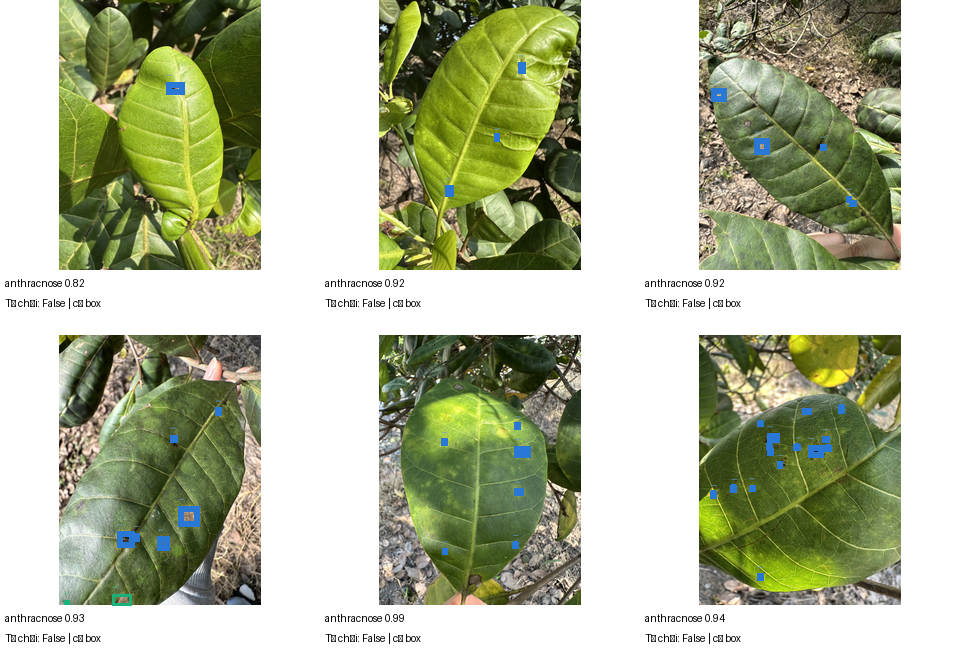

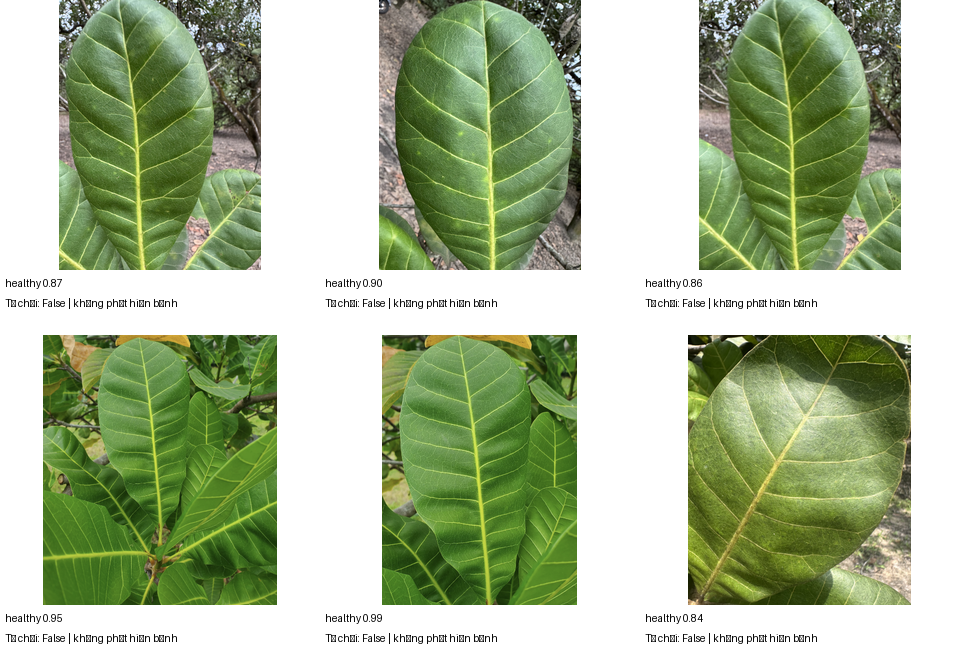

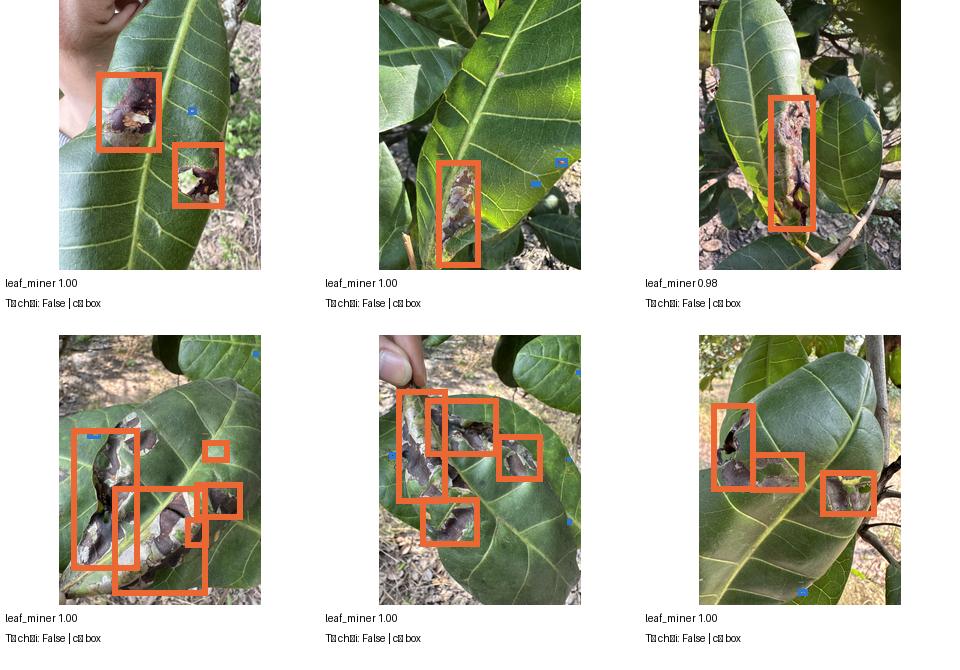

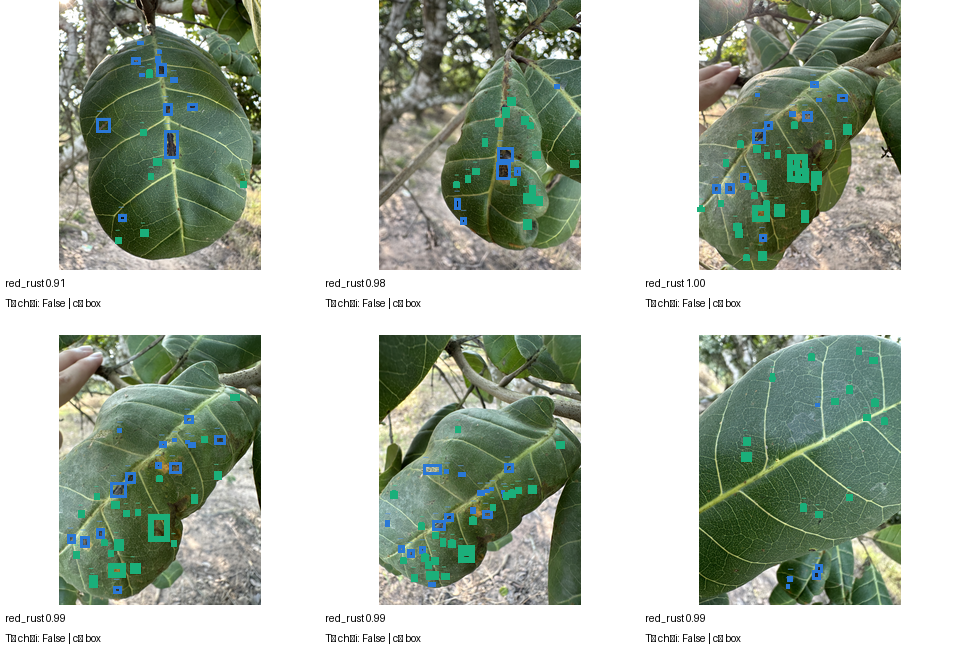

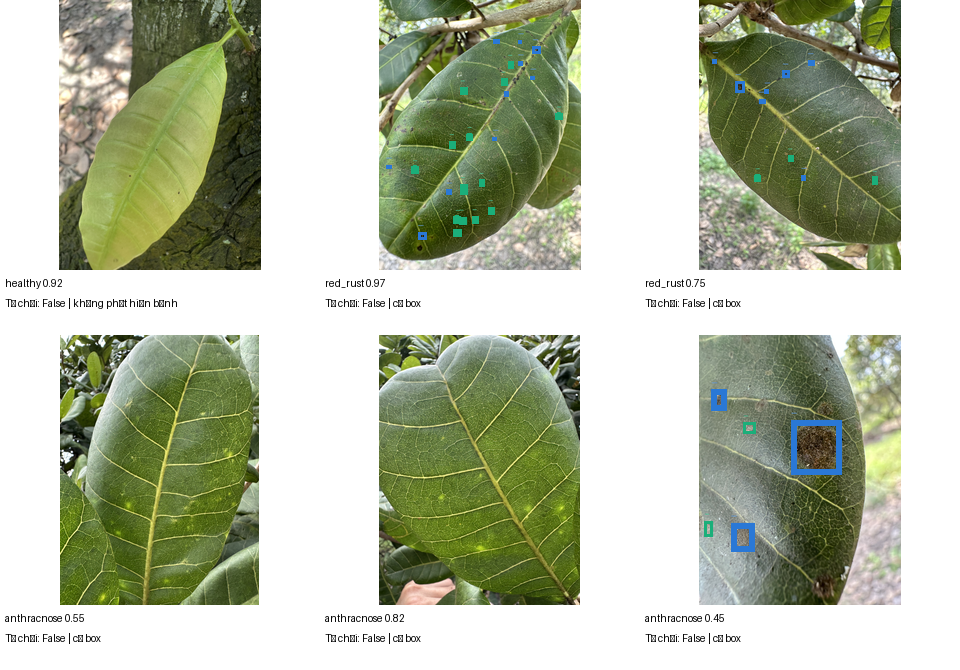

### Kết luận ngắn



YOLO: EXP-Y26S-NEG-V04-001 trên CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip (best.pt SHA-256 f9dc3fba1347b321…); DenseNet121: huấn luyện mới, công thức EXP-034.

Báo cáo này chỉ đánh giá pipeline kết hợp. Không chọn hoặc so sánh phương pháp khác.

Test: 97.1% (Wilson 95% 95.5%–98.1%).

Holdout 09: 94.4% (Wilson 95% 89.0%–97.3%).

Khoảng cách Test–Holdout: 2.6 điểm phần trăm.

C=1; nhiệt độ=0.9317; ngưỡng từ chối=0.4262; BOX_CONF=0.25.

Validation là ngoài fold theo nhóm pHash. Holdout là đánh giá mô tả đã được xem trong EXP-032, không phải blind benchmark.

In [12]:
# EXP-035: training diagnostics and final report for the combined model only.
import matplotlib.pyplot as plt
from PIL import ImageFont
try:
    from IPython.display import display, Markdown
except ImportError:  # Local notebook smoke test without Jupyter.
    def display(value):
        print(value)
    def Markdown(value):
        return value

FIGURES = AGGREGATE / "figures"
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10})

def save_training_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def markdown_table(frame):
    columns = [str(name) for name in frame.columns]
    lines = ["| " + " | ".join(columns) + " |",
             "|" + "|".join("---" for _ in columns) + "|"]
    for row in frame.itertuples(index=False, name=None):
        lines.append("| " + " | ".join(str(item).replace("|", "/") for item in row) + " |")
    return "\n".join(lines)

# These are training diagnostics for the DenseNet component inside this one pipeline.
training_rows, history_rows = [], []
for seed in SEEDS:
    meta = json.loads((OUT_DIR / f"seed_{seed}" / "seed_summary.json").read_text(encoding="utf-8"))
    selected = meta["selected_stage"]
    for stage in meta["stages"]:
        training_rows.append({"seed": seed, "stage": stage["stage"],
            "selected": stage["stage"] == selected, "epochs": int(stage["epochs"]),
            "val_loss": float(stage["val_loss"]), "seconds": float(stage["seconds"]),
            "model_sha256": meta["deployment_sha256"]})
        for epoch, loss in enumerate(stage["history"]["loss"], start=1):
            history_rows.append({"seed": seed, "stage": stage["stage"], "epoch": epoch,
                "loss": float(loss), "val_loss": float(stage["history"]["val_loss"][epoch-1]),
                "accuracy": float(stage["history"]["accuracy"][epoch-1]),
                "val_accuracy": float(stage["history"]["val_accuracy"][epoch-1])})
training_table = pd.DataFrame(training_rows)
history_table = pd.DataFrame(history_rows)
training_table.to_csv(AGGREGATE / "combined_training_stages.csv", index=False)
history_table.to_csv(AGGREGATE / "combined_training_history.csv", index=False)
display(Markdown("### Huấn luyện phần DenseNet trong pipeline kết hợp\n\n" +
                 markdown_table(training_table.round(4))))

fig, axes = plt.subplots(2, len(SEEDS), figsize=(19, 7), sharey="row")
for column, seed in enumerate(SEEDS):
    cursor = 0
    for stage in ("stage1", "stage2"):
        view = history_table[(history_table.seed == seed) & (history_table.stage == stage)]
        x = np.arange(cursor + 1, cursor + len(view) + 1)
        for row, metric, validation in ((0, "loss", "val_loss"),
                                        (1, "accuracy", "val_accuracy")):
            axes[row, column].plot(x, view[metric], color="#2a78d6", label="Huấn luyện")
            axes[row, column].plot(x, view[validation], color="#eb6834", label="Thẩm định")
        cursor += len(view)
        if stage == "stage1":
            for row in (0, 1):
                axes[row, column].axvline(cursor + .5, color="grey", ls="--", lw=.8)
    axes[0, column].set_title(f"Seed {seed}: hàm mất mát")
    axes[1, column].set_title(f"Seed {seed}: độ chính xác")
    for row in (0, 1):
        axes[row, column].set_xlabel("Vòng huấn luyện")
        axes[row, column].grid(alpha=.2)
axes[0, 0].set_ylabel("Hàm mất mát")
axes[1, 0].set_ylabel("Độ chính xác")
axes[0, 0].legend(fontsize=8)
save_training_figure(fig, "00_densenet_component_training_curves.png")

cv = pd.read_csv(AGGREGATE / "stacker_cv_partB.csv")
cv = cv[cv.rule == "F3"].copy()
assert len(cv) == 5 and choiceB["F3"] in set(cv.C)
cv.to_csv(AGGREGATE / "combined_stacker_cv.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cv.C, cv.cv_log_loss, "o-", color="#1baf7a")
ax.axvline(choiceB["F3"], color="grey", ls="--", label=f"C đã khóa = {choiceB['F3']}")
ax.set(xscale="log", xlabel="C của logistic regression",
       ylabel="Log loss ngoài fold", title="Chọn C bằng Validation theo nhóm pHash")
ax.legend()
ax.grid(alpha=.2)
save_training_figure(fig, "00_combined_stacker_grouped_cv.png")

# A fixed-C bootstrap refit measures the stability of this combined stacker only.
refit_rng = np.random.default_rng(34034)
train_x = matrix(cleanB, "F3")
train_y = cleanB.true_label.map(CLASS_INDEX).to_numpy()
hold_x = matrix(holdB, "F3")
hold_y = holdB.true_label.map(CLASS_INDEX).to_numpy()
refit_rows = []
for repeat in range(200):
    for attempt in range(100):
        sample = refit_rng.integers(0, len(cleanB), size=len(cleanB))
        if len(np.unique(train_y[sample])) == len(CLASSES):
            break
    else:
        raise RuntimeError("Bootstrap sample did not contain all five classes")
    model = make_pipeline(StandardScaler(), LogisticRegression(C=choiceB["F3"], max_iter=1500))
    model.fit(train_x[sample], train_y[sample])
    raw = np.zeros((len(holdB), len(CLASSES)))
    raw[:, model[-1].classes_] = model.predict_proba(hold_x)
    pred = apply_temperature(raw, configB["temperature"]["F3"]).argmax(1)
    refit_rows.append({"replicate": repeat, "holdout_accuracy": float(np.mean(pred == hold_y))})
refit = pd.DataFrame(refit_rows)
refit.to_csv(AGGREGATE / "combined_stacker_refit.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(refit.holdout_accuracy * 100, bins=15, color="#1baf7a", edgecolor="white")
ax.axvline(refit.holdout_accuracy.mean() * 100, ls="--", color="black")
ax.set(xlabel="Độ chính xác Holdout (%)", ylabel="Số lần fit lại",
       title="Độ ổn định của phần kết hợp qua 200 lần fit lại")
save_training_figure(fig, "00_combined_stacker_refit.png")

# Final tables contain only the combined rule, including OOF Validation and both Holdout views.
metrics = pd.DataFrame(ALL_RESULTS)
metrics = metrics[(metrics.part == "B") & (metrics.rule == "F3") &
                  (metrics.split.isin(["validation_clean", "test", "holdout", "holdout_n124"]))].copy()
errors = pd.DataFrame(ALL_TAXONOMY)
errors = errors[(errors.part == "B") & (errors.rule == "F3")]
abstention = pd.DataFrame(ALL_ABSTENTION)
abstention = abstention[(abstention.part == "B") & (abstention.rule == "F3")]
table = metrics.merge(errors[["split", "missed_disease", "wrong_disease_type", "false_alarm"]],
                      on="split", validate="one_to_one")
table = table.merge(abstention[["split", "threshold", "coverage", "selective_accuracy",
                               "referred_to_expert"]], on="split", validate="one_to_one")
table = table.drop(columns=["part", "rule"])
table.loc[table.split.str.startswith("holdout"), "recall_not_cashew_leaf"] = np.nan
table.to_csv(AGGREGATE / "combined_results.csv", index=False)
display(Markdown("### Kết quả cuối của DenseNet121 + YOLO\n\n" +
                 markdown_table(table.round(4)) +
                 "\n\nValidation là dự đoán ngoài fold theo nhóm pHash. "
                 "Holdout 09 đã được xem trước, chỉ là đánh giá mô tả."))

# Draw deterministic qualitative panels using the frozen combined pipeline.
_report_bundle = OUT_DIR / "pipeline_bundle"
_report_consistency = AGGREGATE / "pipeline_consistency.json"
if ("pipeline" not in globals() or
        Path(getattr(pipeline, "bundle_dir", "")).resolve() != _report_bundle.resolve()):
    if not _report_consistency.is_file() or not (_report_bundle / "cashew_pipeline.py").is_file():
        raise RuntimeError(
            "Run the pipeline consistency cell immediately before this report cell; "
            "the frozen pipeline bundle is not ready. DenseNet training does not need to be repeated.")
    _report_gate = json.loads(_report_consistency.read_text(encoding="utf-8"))
    if _report_gate.get("status") != "PASS":
        raise RuntimeError("Pipeline consistency did not pass; inspect that cell before reporting")
    import importlib.util
    _report_spec = importlib.util.spec_from_file_location(
        "cashew_pipeline_exp035_report", _report_bundle / "cashew_pipeline.py")
    _report_module = importlib.util.module_from_spec(_report_spec)
    _report_spec.loader.exec_module(_report_module)
    pipeline = _report_module.CashewPipeline(_report_bundle)

box_colors = {"anthracnose": (42, 120, 214), "leaf_miner": (235, 104, 52),
              "red_rust": (27, 175, 122)}
font_path = Path("/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf")
def panel_font(size):
    return ImageFont.truetype(str(font_path), size) if font_path.is_file() else ImageFont.load_default()

def annotated_tile(path, result):
    with Image.open(path) as handle:
        image = ImageOps.exif_transpose(handle).convert("RGB")
    w, h = image.size
    line = max(3, round(.004 * max(w, h)))
    draw = ImageDraw.Draw(image)
    for box in result["boxes"]:
        color = box_colors[box["cls"]]
        width = line * (2 if box["cls"] == result["label"] else 1)
        draw.rectangle(box["xyxy"], outline=color, width=width)
        label = f"{box['cls']} {box['conf']:.2f}"
        size = max(14, round(.018 * max(w, h)))
        pos = (max(0, round(box["xyxy"][0])), max(0, round(box["xyxy"][1] - 1.5*size)))
        bounds = draw.textbbox(pos, label, font=panel_font(size))
        draw.rectangle(bounds, fill=color)
        draw.text(pos, label, fill="white", font=panel_font(size))
    image.thumbnail((300, 270), Image.Resampling.LANCZOS)
    tile = Image.new("RGB", (320, 335), "white")
    xoff = (320-image.width)//2
    tile.paste(image, (xoff, 0))
    draw = ImageDraw.Draw(tile)
    for box in result["boxes"]:
        color = box_colors[box["cls"]]
        rect = [xoff + box["xyxy"][0]*image.width/w, box["xyxy"][1]*image.height/h,
                xoff + box["xyxy"][2]*image.width/w, box["xyxy"][3]*image.height/h]
        draw.rectangle(rect, outline=color, width=max(3, round(line*image.width/w)) *
                       (2 if box["cls"] == result["label"] else 1))
    state = "cần chuyên gia kiểm tra" if result["abstain"] else (
        "không phát hiện bệnh" if result["label"] in ("healthy", "not_cashew_leaf") else "có box")
    draw.text((5, 277), f"{result['label']} {result['confidence']:.2f}",
              fill="black", font=panel_font(14))
    draw.text((5, 297), f"Từ chối: {result['abstain']} | {state}",
              fill="black", font=panel_font(12))
    if result["boxes"]:
        pixels = np.asarray(tile)
        assert any(np.all(pixels == color, axis=2).any() for color in box_colors.values())
    return tile

def save_panel(keys, name):
    canvas = Image.new("RGB", (960, 670), "white")
    inventory = INVENTORY["holdout"].set_index("evidence_key")
    for i, key in enumerate(keys[:6]):
        path = inventory.loc[key, "path"]
        canvas.paste(annotated_tile(path, pipeline.predict(path)), ((i % 3)*320, (i // 3)*335))
    canvas.save(FIGURES / name, dpi=(200, 200))
    display(canvas)

panel_keys = []
for cls in CLASSES[:4]:
    keys = sorted(INVENTORY["holdout"][INVENTORY["holdout"].true_label == cls].evidence_key)[:6]
    save_panel(keys, f"holdout_{cls}.png")
    panel_keys.extend({"panel": cls, "evidence_key": key} for key in keys)
hold_frame, hold_predictions = PART_PREDICTIONS["B"]["holdout"]
hold_true = hold_frame.true_label.map(CLASS_INDEX).to_numpy()
wrong = sorted(hold_frame.evidence_key[hold_predictions["F3"][0] != hold_true])[:6]
save_panel(wrong, "holdout_combined_errors.png")
panel_keys.extend({"panel": "errors", "evidence_key": key} for key in wrong)
pd.DataFrame(panel_keys).to_csv(AGGREGATE / "combined_panel_keys.csv", index=False)

test = table[table.split == "test"].iloc[0]
holdout = table[table.split == "holdout"].iloc[0]
gap = float(test.accuracy - holdout.accuracy)
summary = {"experiment_id": EXPERIMENT_ID, "model": "DenseNet121 + YOLO26s",
    "status": "synthetic dry run" if DRY_RUN else "real run",
    "seeds": SEEDS, "selected_C": float(choiceB["F3"]),
    "temperature": float(configB["temperature"]["F3"]),
    "abstain_threshold": float(configB["abstain_thresholds"]["F3"]),
    "box_conf": float(BOX_CONF), "test_accuracy": float(test.accuracy),
    "test_wilson_95": [float(test.wilson_low), float(test.wilson_high)],
    "holdout_accuracy": float(holdout.accuracy),
    "holdout_wilson_95": [float(holdout.wilson_low), float(holdout.wilson_high)],
    "test_minus_holdout": gap,
    "holdout_n": int(holdout.n),
    "detector": DETECTOR_NAME, "yolo_dataset": YOLO_DATASET_ARCHIVE_NAME,
    "seed_models_source": SEED_MODELS_SOURCE_EXPERIMENT_ID or EXPERIMENT_ID,
    "source_hashes": {"split13": DATASET_ARCHIVE_SHA256,
                      "yolo_dataset": YOLO_DATASET_SHA256,
                      "detector_weights": DETECTOR_WEIGHTS_SHA256}}
write_json(AGGREGATE / "combined_summary.json", summary)
readme = ["# DenseNet121 + YOLO26s (NEG_V04) — EXP-035", "",
          f"YOLO: {DETECTOR_NAME} trên {YOLO_DATASET_ARCHIVE_NAME} (best.pt SHA-256 {DETECTOR_WEIGHTS_SHA256[:16]}…); "
          f"DenseNet121: {SEED_MODELS_SOURCE_EXPERIMENT_ID or 'huấn luyện mới, công thức EXP-034'}.",
          "Báo cáo này chỉ đánh giá pipeline kết hợp. Không chọn hoặc so sánh phương pháp khác.",
          f"Test: {test.accuracy:.1%} (Wilson 95% {test.wilson_low:.1%}–{test.wilson_high:.1%}).",
          f"Holdout 09: {holdout.accuracy:.1%} (Wilson 95% {holdout.wilson_low:.1%}–{holdout.wilson_high:.1%}).",
          f"Khoảng cách Test–Holdout: {gap*100:.1f} điểm phần trăm.",
          f"C={choiceB['F3']}; nhiệt độ={configB['temperature']['F3']:.4f}; "
          f"ngưỡng từ chối={configB['abstain_thresholds']['F3']:.4f}; BOX_CONF={BOX_CONF:.2f}.",
          "Validation là ngoài fold theo nhóm pHash. Holdout là đánh giá mô tả đã được xem trong EXP-032, không phải blind benchmark.",
          "Holdout không có ground truth box; chất lượng box chỉ đo trên YOLO Test.",
          "Các bảng CSV và hình PNG nằm trong aggregate/. Hai ZIP chứa pipeline và báo cáo consistency."]
if DRY_RUN:
    readme.append("DRY RUN tổng hợp: detector giả lập, 2 seed, 1 epoch mỗi giai đoạn; không phải kết quả thật.")
(AGGREGATE / "README.md").write_text("\n\n".join(readme) + "\n", encoding="utf-8")
display(Markdown("### Kết luận ngắn\n\n" + "\n\n".join(readme[1:9])))


## Xuất kết quả

Cell tiếp theo kiểm tra đầy đủ artifact, tạo hai ZIP và upload lên Google Drive.


In [13]:
# EXP-035 final audit, immutable FULL/ANALYSIS ZIPs, and verified Drive upload.
if not (AGGREGATE / "pipeline_consistency.json").is_file():
    raise RuntimeError("Pipeline consistency gate has not passed")
consistency = json.loads((AGGREGATE / "pipeline_consistency.json").read_text(encoding="utf-8"))
if consistency.get("status") != "PASS" or consistency.get("holdout_images", 0) < min(20, len(INVENTORY["holdout"])):
    raise RuntimeError("Pipeline consistency report is incomplete")

if USE_EXTRA_BLIND_SET:
    if not EXTRA_BLIND_DRIVE_FOLDER_ID.strip():
        raise ValueError("Set EXTRA_BLIND_DRIVE_FOLDER_ID for the optional blind set")
    from googleapiclient.http import MediaIoBaseDownload
    blind_service = drive_client()
    blind_root = STAGE_ROOT / "blind10"
    blind_root.mkdir(parents=True, exist_ok=True)
    def copy_folder(folder_id, target):
        page = None
        while True:
            response = blind_service.files().list(
                q=f"'{folder_id}' in parents and trashed = false",
                fields="nextPageToken,files(id,name,mimeType,size)", pageToken=page,
                pageSize=1000, supportsAllDrives=True,
                includeItemsFromAllDrives=True).execute()
            for item in response["files"]:
                dest = target / item["name"]
                assert dest.resolve().is_relative_to(blind_root.resolve())
                if item["mimeType"] == "application/vnd.google-apps.folder":
                    dest.mkdir(exist_ok=True)
                    copy_folder(item["id"], dest)
                else:
                    request = blind_service.files().get_media(fileId=item["id"], supportsAllDrives=True)
                    with dest.open("wb") as stream:
                        download = MediaIoBaseDownload(stream, request, chunksize=8 << 20)
                        done = False
                        while not done:
                            _, done = download.next_chunk(num_retries=3)
                    assert dest.stat().st_size == int(item["size"])
            page = response.get("nextPageToken")
            if not page:
                break
    copy_folder(EXTRA_BLIND_DRIVE_FOLDER_ID, blind_root)
    blind_rows = [{"key": p.relative_to(blind_root).as_posix(),
                   "true": p.parent.name, "pred": pipeline.predict(p)["label"]}
                  for p in image_files(blind_root)]
    pd.DataFrame(blind_rows).to_csv(AGGREGATE / "blind_predictions.csv", index=False)
    blind_acc = np.mean([r["true"] == r["pred"] for r in blind_rows]) if blind_rows else np.nan
    (AGGREGATE / "blind_report.md").write_text(
        f"# Frozen optional blind set\n\nN={len(blind_rows)}, accuracy={blind_acc:.4f}. "
        "No selection or threshold change.\n", encoding="utf-8")

required = ["combined_results.csv", "combined_training_stages.csv",
            "combined_training_history.csv", "combined_stacker_cv.csv",
            "combined_summary.json", "pipeline_consistency.json", "README.md",
            "frozen_config.json", "validation_selection_lock.json",
            "localization_test.csv", "combined_gap_bootstrap.csv"]
for name in required:
    if not (AGGREGATE / name).is_file():
        raise FileNotFoundError(AGGREGATE / name)
expected_figures = [
    *(f"combined_only/{name}" for name in (
        "01_accuracy_and_gap.png", "02_class_recall.png", "03_confusion_matrices.png",
        "04_error_types.png", "05_calibration.png", "06_risk_coverage.png",
        "07_confidence_distribution.png", "08_fused_display_localization.png")),
    "00_densenet_component_training_curves.png",
    "00_combined_stacker_grouped_cv.png", "00_combined_stacker_refit.png",
    *(f"holdout_{cls}.png" for cls in CLASSES[:4]),
    "holdout_combined_errors.png"]
missing_figures = [name for name in expected_figures
                   if not (AGGREGATE / "figures" / name).is_file()]
if missing_figures:
    raise RuntimeError(
        "Missing report PNGs: " + ", ".join(missing_figures) +
        ". Run the statistical figures cell, then the combined training report cell, "
        "and retry this export cell. The saved models do not need retraining.")
assert (OUT_DIR / "cashew_pipeline.py").is_file()
assert all((OUT_DIR / "pipeline_bundle" / f"seed_{seed}" / "deployment_model.keras").is_file()
           for seed in SEEDS)

analysis_files = sorted([p for p in AGGREGATE.rglob("*") if p.is_file()] +
    [OUT_DIR / "cashew_pipeline.py", OUT_DIR / "pipeline_bundle" / "frozen_config.json",
     OUT_DIR / "pipeline_bundle" / "decision.json",
     OUT_DIR / "pipeline_bundle" / "artifact_sha256.csv"] +
    [p for seed in SEEDS for p in (OUT_DIR / f"seed_{seed}").glob("*_predictions.csv")] +
    [OUT_DIR / f"seed_{seed}" / "seed_summary.json" for seed in SEEDS])
analysis_manifest = [{"path": p.relative_to(OUT_DIR).as_posix(), "bytes": p.stat().st_size,
                      "sha256": file_sha256(p)} for p in analysis_files]
write_json(AGGREGATE / "analysis_manifest.json", analysis_manifest)
analysis_files = sorted(set(analysis_files + [AGGREGATE / "analysis_manifest.json"]))
full_files = sorted(p for p in OUT_DIR.rglob("*") if p.is_file())

def make_archive(files, suffix):
    import tempfile
    destination = OUT_DIR.parent / f"{OUT_DIR.name}_{suffix}.zip"
    with tempfile.NamedTemporaryFile(dir=OUT_DIR.parent, suffix=".zip.part", delete=False) as handle:
        temporary = Path(handle.name)
    try:
        with zipfile.ZipFile(temporary, "w", zipfile.ZIP_DEFLATED,
                             compresslevel=6, allowZip64=True) as archive:
            for path in files:
                member = f"{OUT_DIR.name}/{path.relative_to(OUT_DIR).as_posix()}"
                info = zipfile.ZipInfo(member, date_time=(1980, 1, 1, 0, 0, 0))
                info.compress_type = zipfile.ZIP_DEFLATED
                with path.open("rb") as source, archive.open(info, "w") as target:
                    shutil.copyfileobj(source, target, length=8 << 20)
        with zipfile.ZipFile(temporary) as archive:
            if archive.testzip() is not None:
                raise RuntimeError(f"{suffix} ZIP CRC verification failed")
            names = set(archive.namelist())
            assert len(names) == len(files)
            assert all(f"{OUT_DIR.name}/{p.relative_to(OUT_DIR).as_posix()}" in names for p in files)
        if destination.exists():
            if file_sha256(destination) != file_sha256(temporary):
                raise RuntimeError(f"Existing {suffix} ZIP differs; do not overwrite: {destination}")
        else:
            temporary.replace(destination)
    finally:
        temporary.unlink(missing_ok=True)
    print(suffix, "ZIP", destination, "bytes", destination.stat().st_size,
          "SHA256", file_sha256(destination))
    return destination

analysis_zip = make_archive(analysis_files, "ANALYSIS")
full_zip = make_archive(full_files, "FULL")
if UPLOAD_RESULT_ZIPS_TO_DRIVE:
    upload_service = drive_client()
    for path in (analysis_zip, full_zip):
        file_id = upload_immutable(upload_service, path)
        remote = upload_service.files().get(fileId=file_id,
            fields="id,name,size,md5Checksum,parents,webViewLink",
            supportsAllDrives=True).execute()
        if (remote["name"] != path.name or int(remote["size"]) != path.stat().st_size or
                remote.get("md5Checksum") != file_md5(path) or
                DRIVE_TARGET_FOLDER_ID not in remote.get("parents", [])):
            raise RuntimeError(f"Drive verification failed: {path.name}")
        print("Drive verified:", remote.get("webViewLink") or
              f"https://drive.google.com/file/d/{file_id}/view")
else:
    print("Drive upload disabled; ZIPs remain local only")


ANALYSIS ZIP /content/training_results/current_dataset/EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_ANALYSIS.zip bytes 22794692 SHA256 27b5ea684d99dc8b160e7eac0694ba1a7e647789f158807f576e14a1fe208aca
FULL ZIP /content/training_results/current_dataset/EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_FULL.zip bytes 778131367 SHA256 816035c131eec5da1e09ec89f98b6160b2c3bf89f37f6883faa6bdfe9f04dd32


Verified upload EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_ANALYSIS.zip 1o35xd-vrqE3LaAJBCxKesq3pIogBFbb_
Drive verified: https://drive.google.com/file/d/1o35xd-vrqE3LaAJBCxKesq3pIogBFbb_/view?usp=drivesdk
Verified upload EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_FULL.zip 1IH_UpiGLikCoPoWWuHtxUhsS8gDD_6lb
Drive verified: https://drive.google.com/file/d/1IH_UpiGLikCoPoWWuHtxUhsS8gDD_6lb/view?usp=drivesdk
